# 05 — Edge-Weight Analysis

This notebook investigates the role of edge-weight representation and weight
diversity in the Max-Cut benchmark instances.

The analysis focuses on two main questions:

1. How are the benchmark instances distributed across different edge-weight
   categories, including integer-weighted, non-integer-weighted, and
   unique-weight-dominance groups?

2. How does the dominance of unique or repeated edge weights influence solver
   performance across DAv3c, DAv2, DAv3, and the selected MQLib heuristics?

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

#project imports
sys.path.append(str(Path("../src/maxcut").resolve()))

%load_ext autoreload
%autoreload 2

import config as cfg
import utils
import plotting
plotting.set_plot_style()
print(f"Figures will be saved to: {cfg.FIGURE_DIR}")

Figures will be saved to: /Users/sargun/Desktop/DAMB-DAv3c/results/figures


In [2]:
# Paths
PATH_BASELINE = (
    cfg.PROCESSED_DIR / "baseline_dataset.csv"
)

UW_PATH = (
    cfg.PROCESSED_DIR / "graph_weight_concentration_metrics.parquet"
)

In [3]:
df_unique_wt = pd.read_parquet(UW_PATH)
len(df_unique_wt)

3506

In [4]:
df_unique_wt.head()

,name,nodes,edges,density,limit,has_leafs,int_only,r,n80,n85,n90,n95,unique_ratio,singleton_edge_fraction,concentration_group
0,G55,4969,12498,0.001013,13.945,True,True,1,1,1,1,1,0.000080,0.0,Uniform
1,G56,4969,12498,0.001013,13.922,True,True,2,2,2,2,2,0.000160,0.0,Concentrated
2,G57,5000,10000,0.000800,11.299,False,True,2,2,2,2,2,0.000200,0.0,Concentrated
3,G58,5000,29570,0.002366,11.876,False,True,1,1,1,1,1,0.000034,0.0,Uniform
4,G59,5000,29570,0.002366,15.875,False,True,2,2,2,2,2,0.000068,0.0,Concentrated


In [5]:
df_baseline = pd.read_csv(PATH_BASELINE)
df_baseline.head()

,name,nodes,edges,density,limit,has_leafs,int_only,size_cat,density_cat,heuristics_name,...,neg_wt_sum,neg_wt_ratio,triangle_count,has_triangles,transitivity,average_clustering,cyclomatic_number,bridge_count,bridge_fraction,unique_weights
0,G55,4969,12498,0.001013,13.945,True,True,large,sparse,BURER2002,...,0.0,0.000000,23,True,0.001100,0.001189,7530,180,0.014402,1
1,G56,4969,12498,0.001013,13.922,True,True,large,sparse,BURER2002,...,-6276.0,0.502160,23,True,0.001100,0.001189,7530,180,0.014402,2
2,G57,5000,10000,0.000800,11.299,False,True,large,sparse,BURER2002,...,-5019.0,0.501900,0,False,0.000000,0.000000,5001,0,0.000000,2
3,G58,5000,29570,0.002366,11.876,False,True,large,sparse,BURER2002,...,0.0,0.000000,30784,True,0.098091,0.326822,24571,0,0.000000,1
4,G59,5000,29570,0.002366,15.875,False,True,large,sparse,BURER2002,...,-14737.0,0.498377,30784,True,0.098091,0.326822,24571,0,0.000000,2


In [6]:
df_baseline.columns

Index(['name', 'nodes', 'edges', 'density', 'limit', 'has_leafs', 'int_only',
       'size_cat', 'density_cat', 'heuristics_name', 'DAv2', 'DAv2_runtime',
       'DAv3', 'DAv3_runtime', 'DAv3c', 'DAv3c_runtime', 'BURER2002',
       'BURER2002_runtime', 'MERZ1999GLS', 'MERZ1999GLS_runtime',
       'PAL2004bMTS2', 'PAL2004bMTS2_runtime', 'heuristic',
       'heuristic_runtime', 'baseline_objective', 'best_solvers', 'bipartite',
       'neg_edges', 'neg_edges_frac', 'neg_wt_sum', 'neg_wt_ratio',
       'triangle_count', 'has_triangles', 'transitivity', 'average_clustering',
       'cyclomatic_number', 'bridge_count', 'bridge_fraction',
       'unique_weights'],
      dtype='str')

In [7]:
len(df_baseline)

3400

In [8]:
new_cols = ["name"] + [
    col for col in df_baseline.columns
    if col not in df_unique_wt.columns
]

df_final = df_unique_wt.merge(
    df_baseline[new_cols],
    on="name"
)

In [9]:
df_final.head()

,name,nodes,edges,density,limit,has_leafs,int_only,r,n80,n85,...,neg_wt_sum,neg_wt_ratio,triangle_count,has_triangles,transitivity,average_clustering,cyclomatic_number,bridge_count,bridge_fraction,unique_weights
0,G55,4969,12498,0.001013,13.945,True,True,1,1,1,...,0.0,0.000000,23,True,0.001100,0.001189,7530,180,0.014402,1
1,G56,4969,12498,0.001013,13.922,True,True,2,2,2,...,-6276.0,0.502160,23,True,0.001100,0.001189,7530,180,0.014402,2
2,G57,5000,10000,0.000800,11.299,False,True,2,2,2,...,-5019.0,0.501900,0,False,0.000000,0.000000,5001,0,0.000000,2
3,G58,5000,29570,0.002366,11.876,False,True,1,1,1,...,0.0,0.000000,30784,True,0.098091,0.326822,24571,0,0.000000,1
4,G59,5000,29570,0.002366,15.875,False,True,2,2,2,...,-14737.0,0.498377,30784,True,0.098091,0.326822,24571,0,0.000000,2


In [10]:
df_filter = utils.filter_main_instances(df_final)

In [11]:
df_filter.columns

Index(['name', 'nodes', 'edges', 'density', 'limit', 'has_leafs', 'int_only',
       'r', 'n80', 'n85', 'n90', 'n95', 'unique_ratio',
       'singleton_edge_fraction', 'concentration_group', 'size_cat',
       'density_cat', 'heuristics_name', 'DAv2', 'DAv2_runtime', 'DAv3',
       'DAv3_runtime', 'DAv3c', 'DAv3c_runtime', 'BURER2002',
       'BURER2002_runtime', 'MERZ1999GLS', 'MERZ1999GLS_runtime',
       'PAL2004bMTS2', 'PAL2004bMTS2_runtime', 'heuristic',
       'heuristic_runtime', 'baseline_objective', 'best_solvers', 'bipartite',
       'neg_edges', 'neg_edges_frac', 'neg_wt_sum', 'neg_wt_ratio',
       'triangle_count', 'has_triangles', 'transitivity', 'average_clustering',
       'cyclomatic_number', 'bridge_count', 'bridge_fraction',
       'unique_weights'],
      dtype='str')

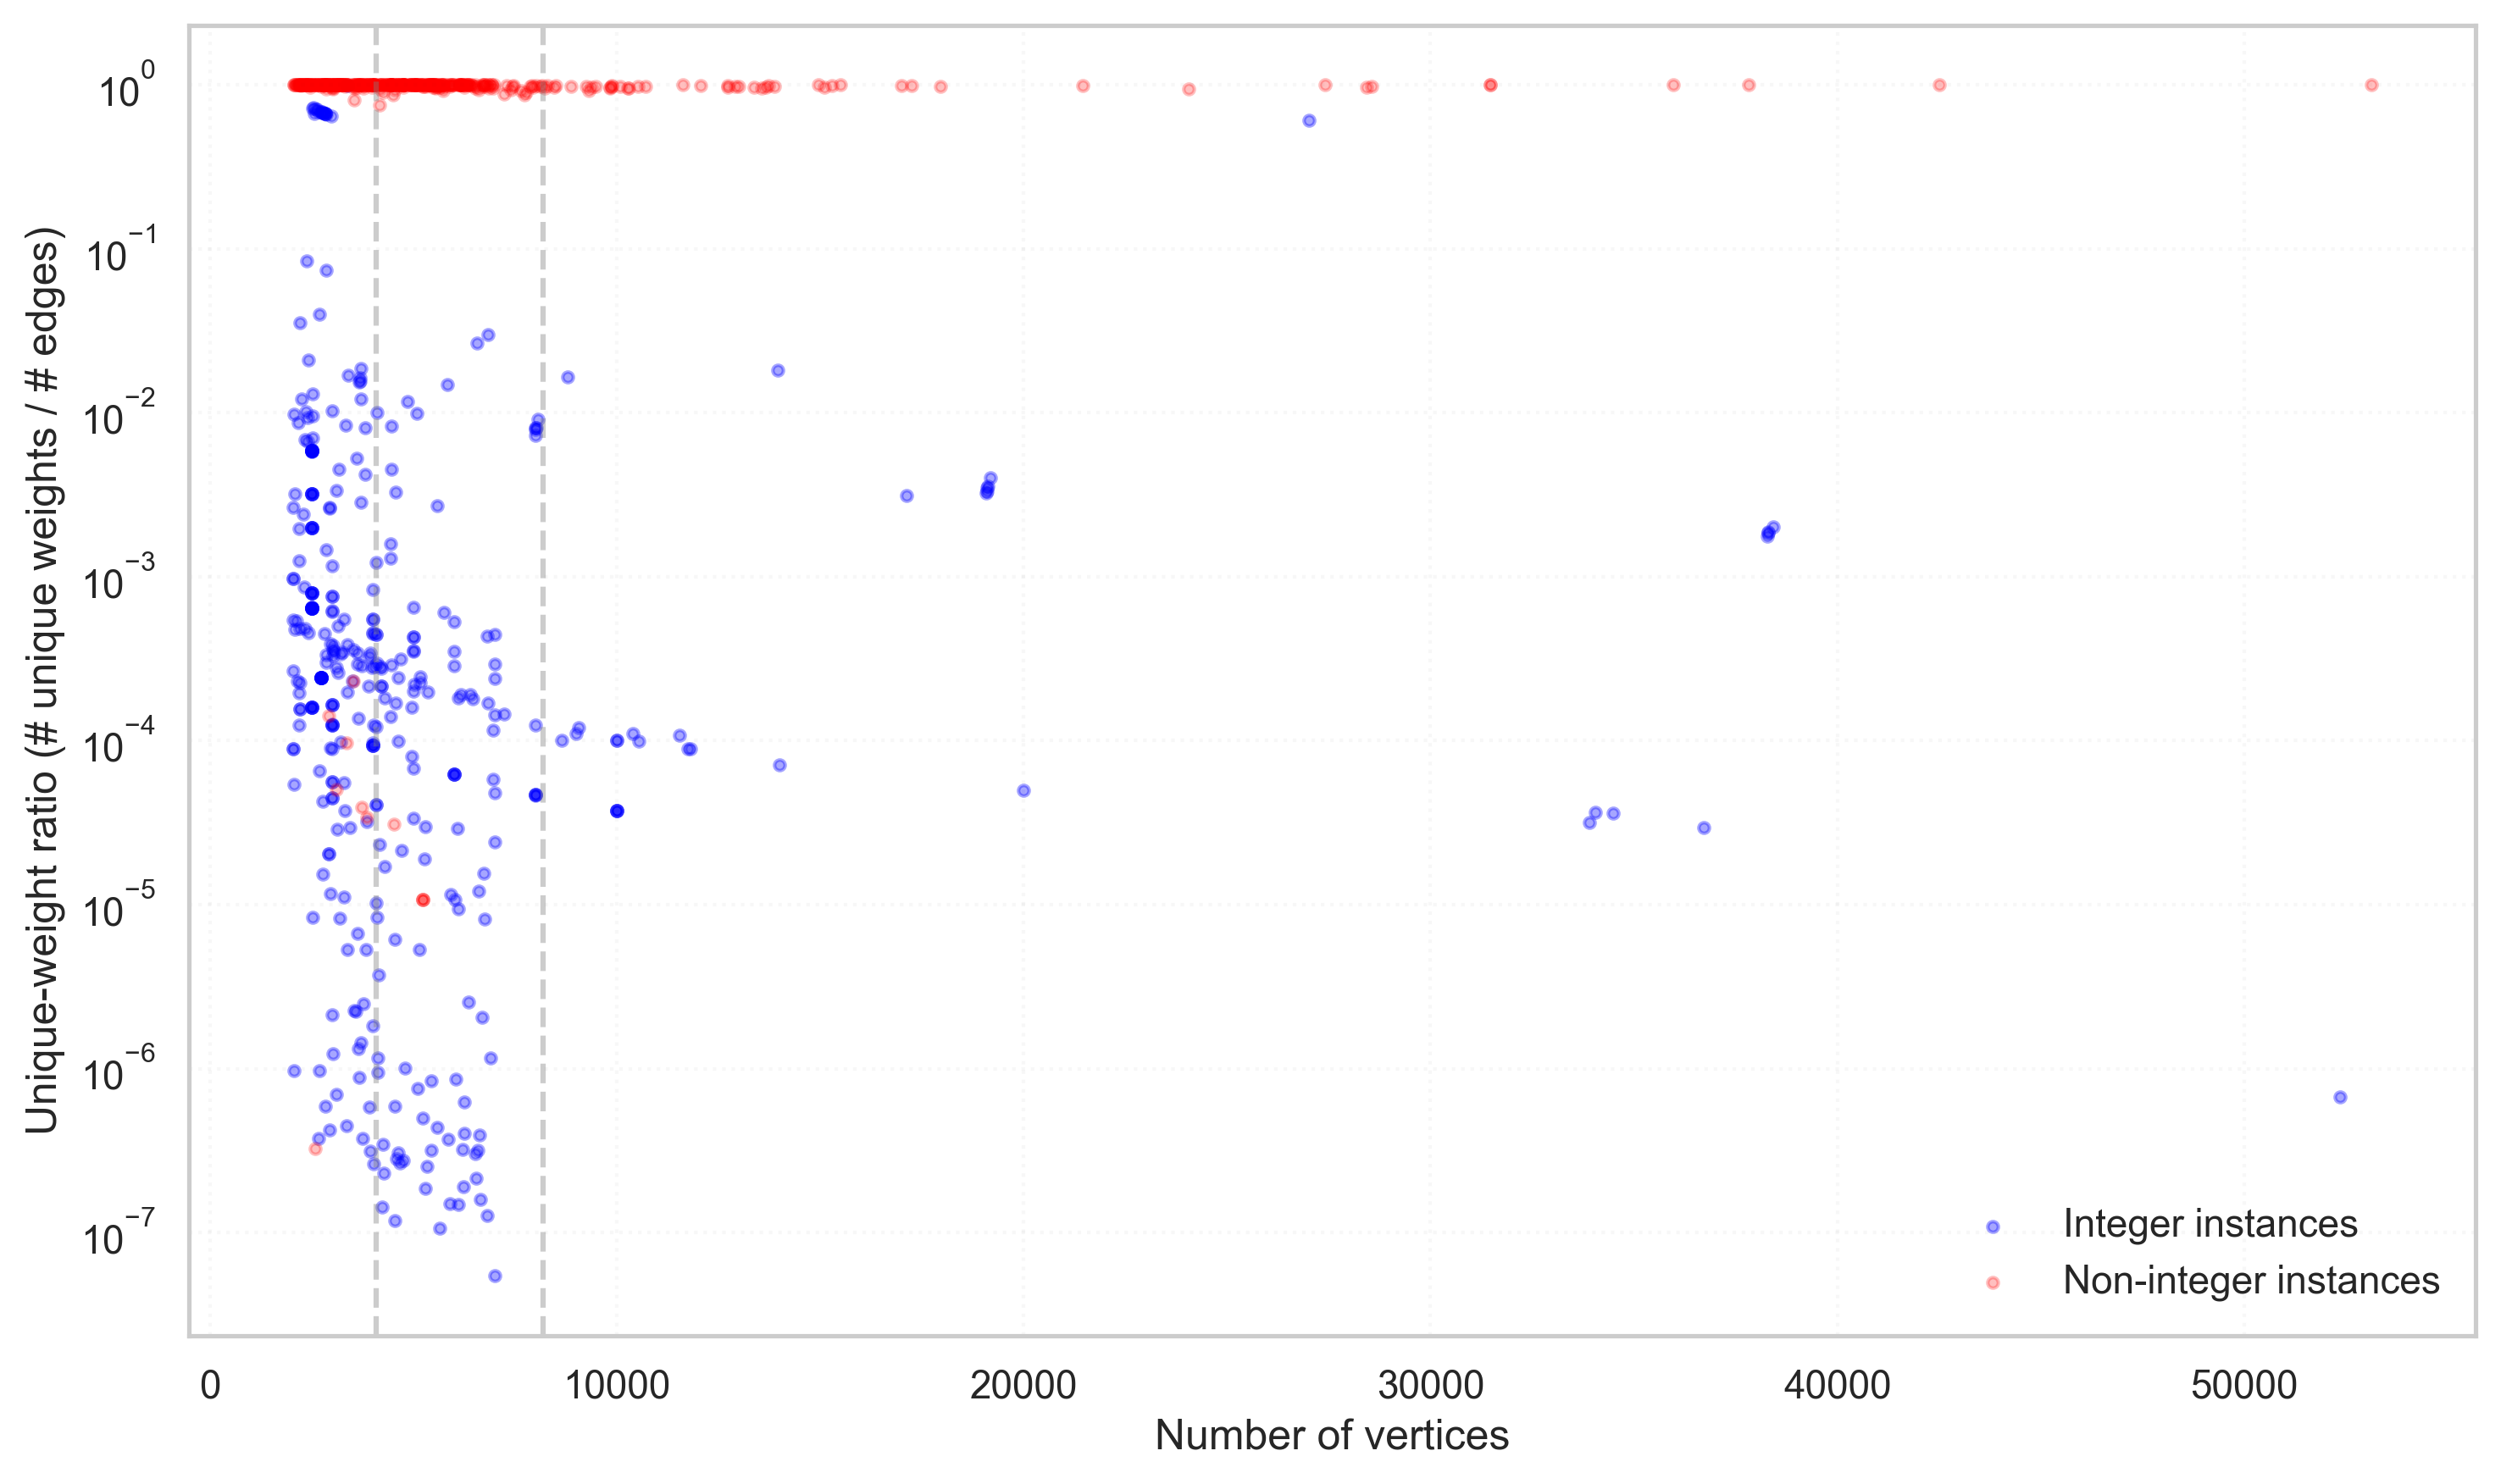

In [12]:
df_weight_ratio = plotting.plot_normalized_edge_weight_distribution(
    df_filter,
    nodes_col="nodes",
    unique_weights_col="unique_weights",
    edges_col="edges",
    int_only_col="int_only",
    file_name="normalized_edge_weight_distribution.png"
)

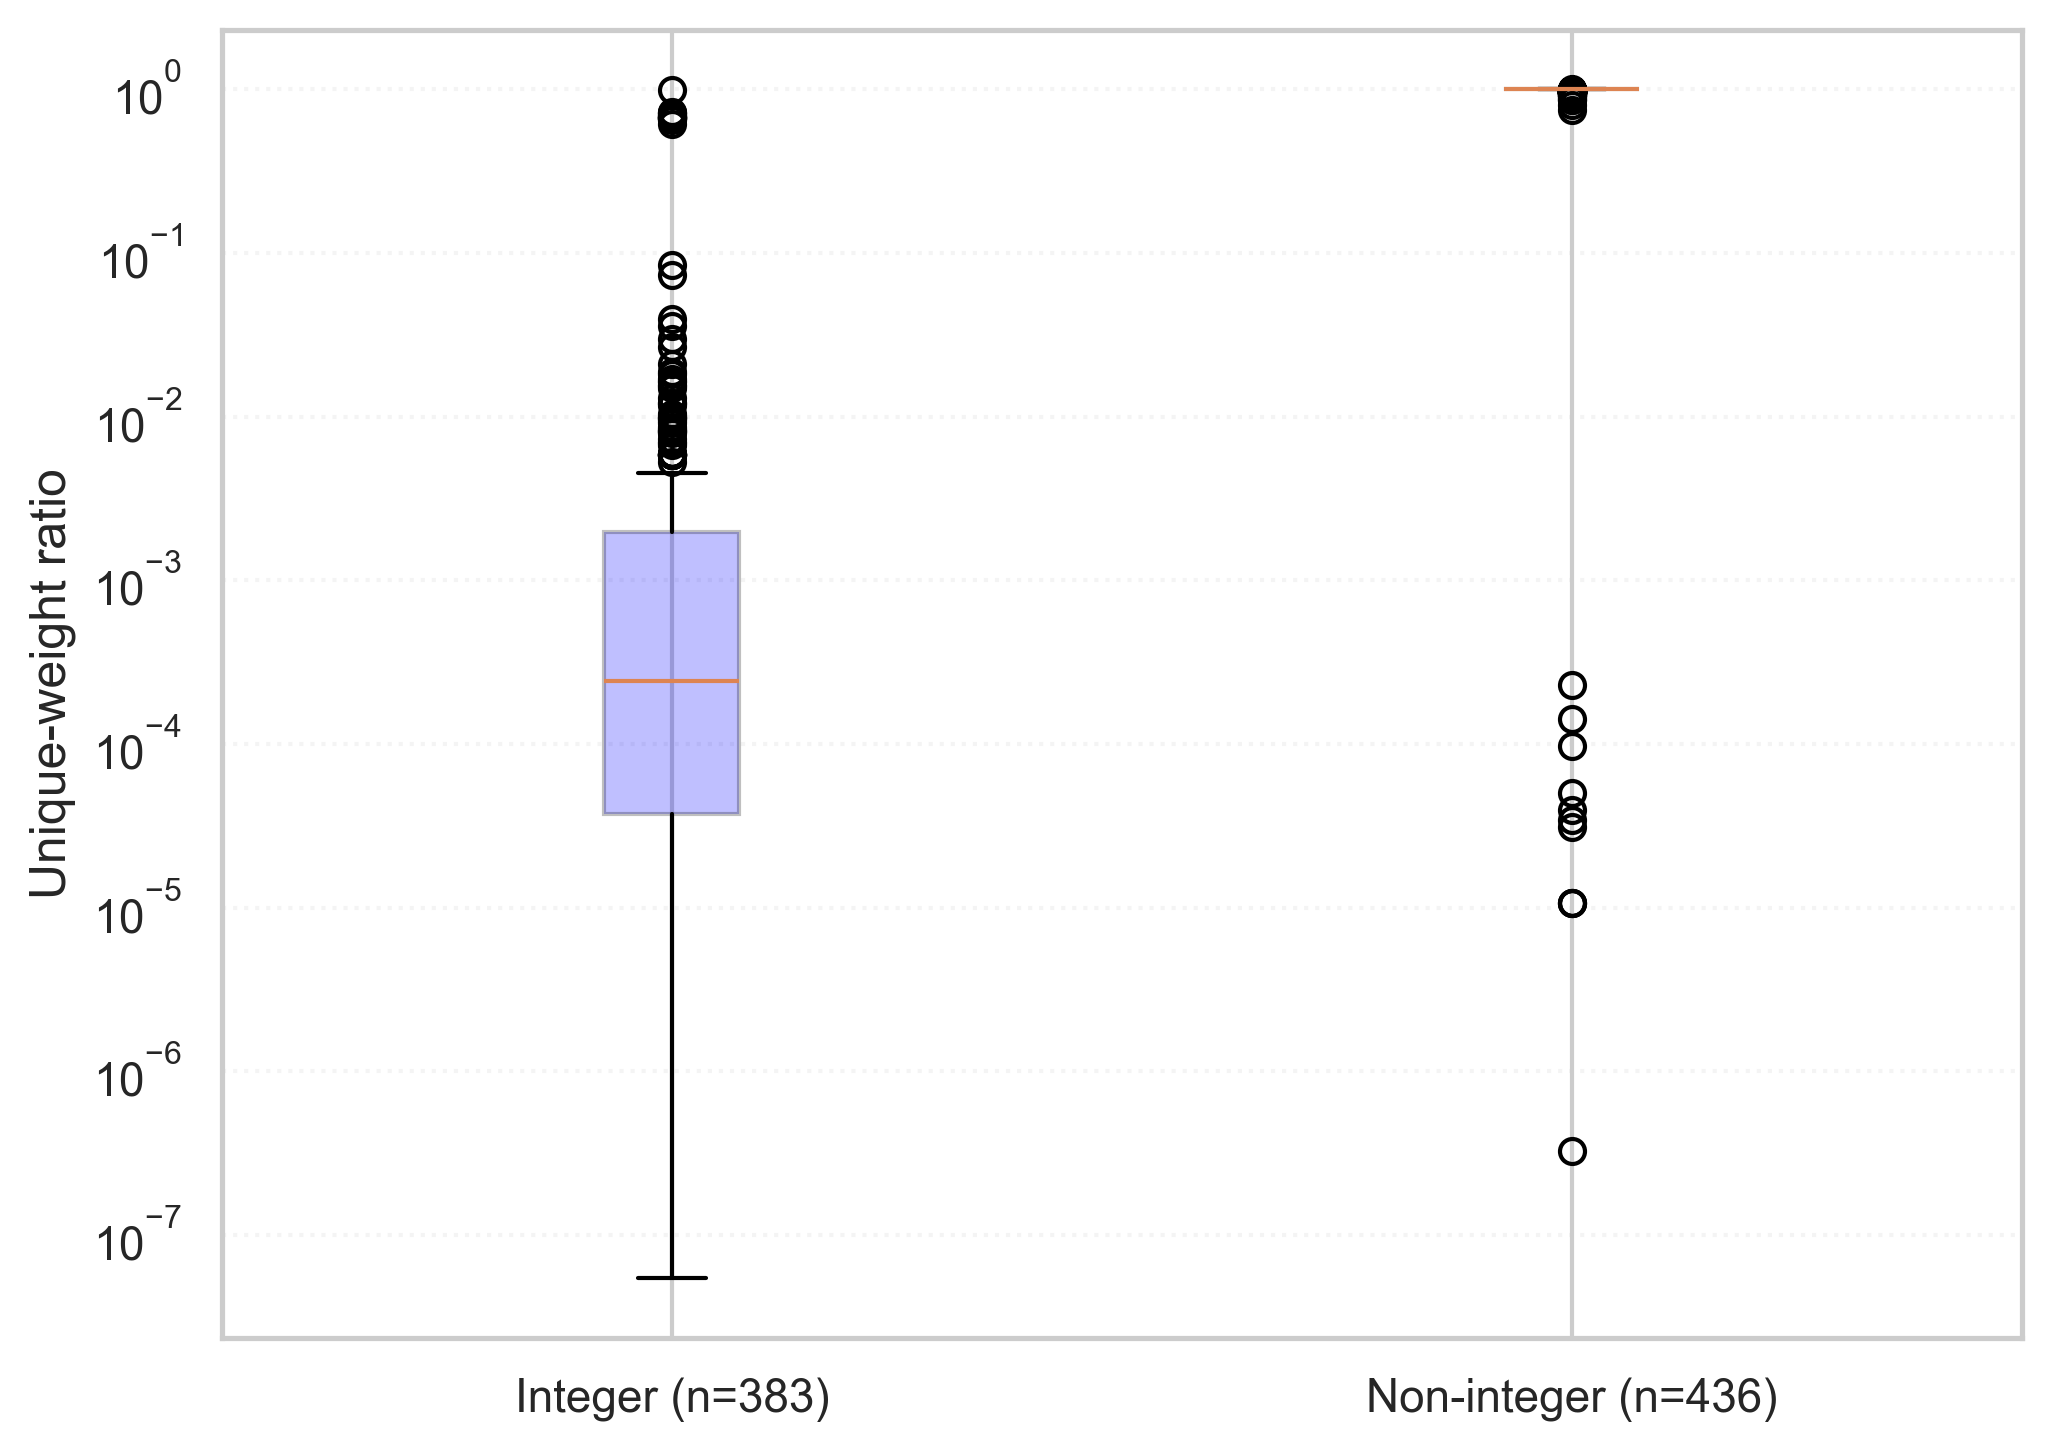

In [13]:
plotting.plot_weight_diversity_boxplot(
    df_weight_ratio,
    file_name="weight_diversity_by_representation.png"
)

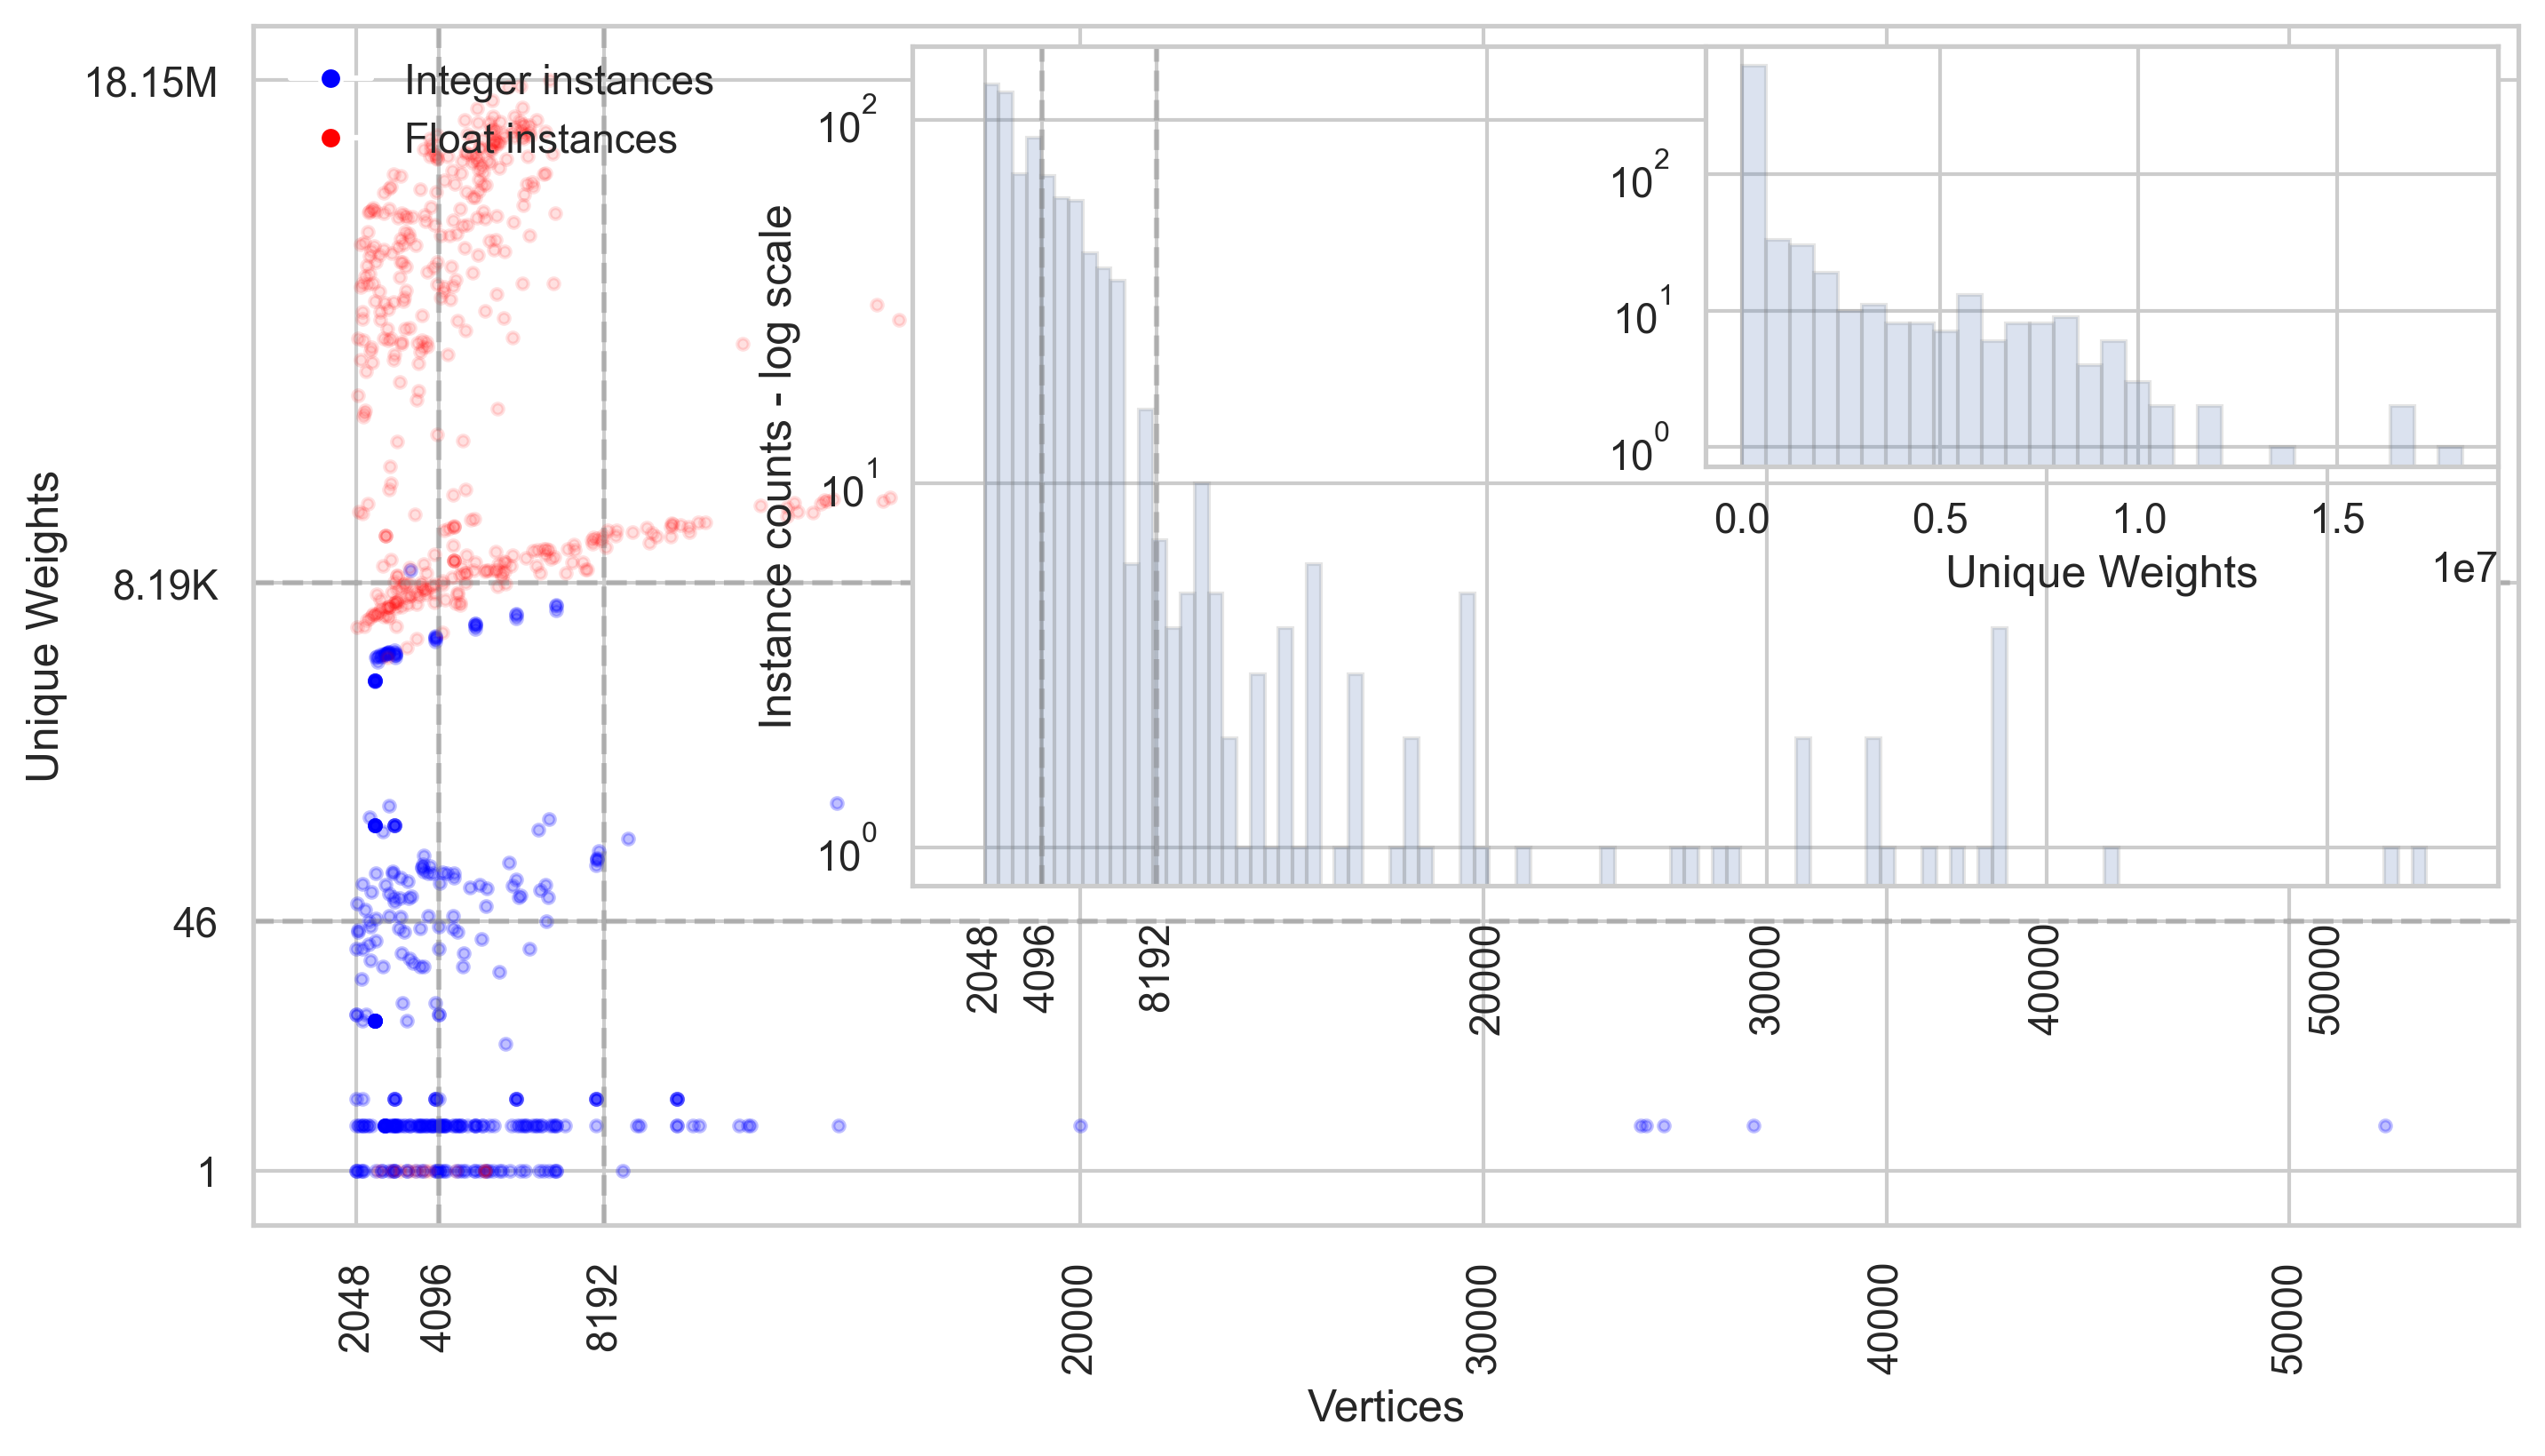

In [14]:
plotting.plot_edge_weight_distribution(df_filter,nodes_col="nodes",unique_weights_col="unique_weights",int_only_col="int_only",file_name='Unique weight-density distribution.png')

In [15]:
df_filter["unique_ratio"] = (
    df_filter["unique_weights"] / df_filter["edges"]
)

In [16]:
df_filter = df_filter.dropna(subset=cfg.SOLVERS)

In [17]:
df_filter['size_cat'].value_counts()

size_cat
medium    407
large     331
Name: count, dtype: int64

In [18]:
df_filter['density_cat'].value_counts()

density_cat
sparse      450
balanced    197
dense        91
Name: count, dtype: int64

In [19]:
df_filter['int_only'].value_counts()

int_only
False    389
True     349
Name: count, dtype: int64

In [20]:
len(df_filter)

738

In [21]:
df_int = df_filter[df_filter["int_only"] == True]
df_float = df_filter[df_filter["int_only"] == False]

In [22]:
df_int.columns

Index(['name', 'nodes', 'edges', 'density', 'limit', 'has_leafs', 'int_only',
       'r', 'n80', 'n85', 'n90', 'n95', 'unique_ratio',
       'singleton_edge_fraction', 'concentration_group', 'size_cat',
       'density_cat', 'heuristics_name', 'DAv2', 'DAv2_runtime', 'DAv3',
       'DAv3_runtime', 'DAv3c', 'DAv3c_runtime', 'BURER2002',
       'BURER2002_runtime', 'MERZ1999GLS', 'MERZ1999GLS_runtime',
       'PAL2004bMTS2', 'PAL2004bMTS2_runtime', 'heuristic',
       'heuristic_runtime', 'baseline_objective', 'best_solvers', 'bipartite',
       'neg_edges', 'neg_edges_frac', 'neg_wt_sum', 'neg_wt_ratio',
       'triangle_count', 'has_triangles', 'transitivity', 'average_clustering',
       'cyclomatic_number', 'bridge_count', 'bridge_fraction',
       'unique_weights'],
      dtype='str')

In [23]:
df_int['heuristics_name'].value_counts()

heuristics_name
BURER2002              242
PALUBECKIS2004bMST2    107
Name: count, dtype: int64

In [24]:
df_int.groupby("concentration_group")["density_cat"].value_counts()

concentration_group  density_cat
Concentrated         sparse         94
                     balanced       20
                     dense           9
Heterogeneous        sparse         62
                     dense          22
                     balanced       20
Transitional         sparse         62
                     balanced        7
                     dense           4
Uniform              sparse         24
                     balanced       19
                     dense           6
Name: count, dtype: int64

In [25]:
df_int.groupby("concentration_group")["size_cat"].value_counts()

concentration_group  size_cat
Concentrated         medium      67
                     large       56
Heterogeneous        medium      74
                     large       30
Transitional         medium      54
                     large       19
Uniform              large       27
                     medium      22
Name: count, dtype: int64

In [26]:
df_int.groupby("concentration_group")["heuristics_name"].value_counts()

concentration_group  heuristics_name    
Concentrated         BURER2002              94
                     PALUBECKIS2004bMST2    29
Heterogeneous        BURER2002              62
                     PALUBECKIS2004bMST2    42
Transitional         BURER2002              62
                     PALUBECKIS2004bMST2    11
Uniform              PALUBECKIS2004bMST2    25
                     BURER2002              24
Name: count, dtype: int64

In [27]:
df_float['concentration_group'].value_counts()

concentration_group
Heterogeneous    378
Uniform           11
Name: count, dtype: int64

In [28]:
df_int['concentration_group'].value_counts()

concentration_group
Concentrated     123
Heterogeneous    104
Transitional      73
Uniform           49
Name: count, dtype: int64

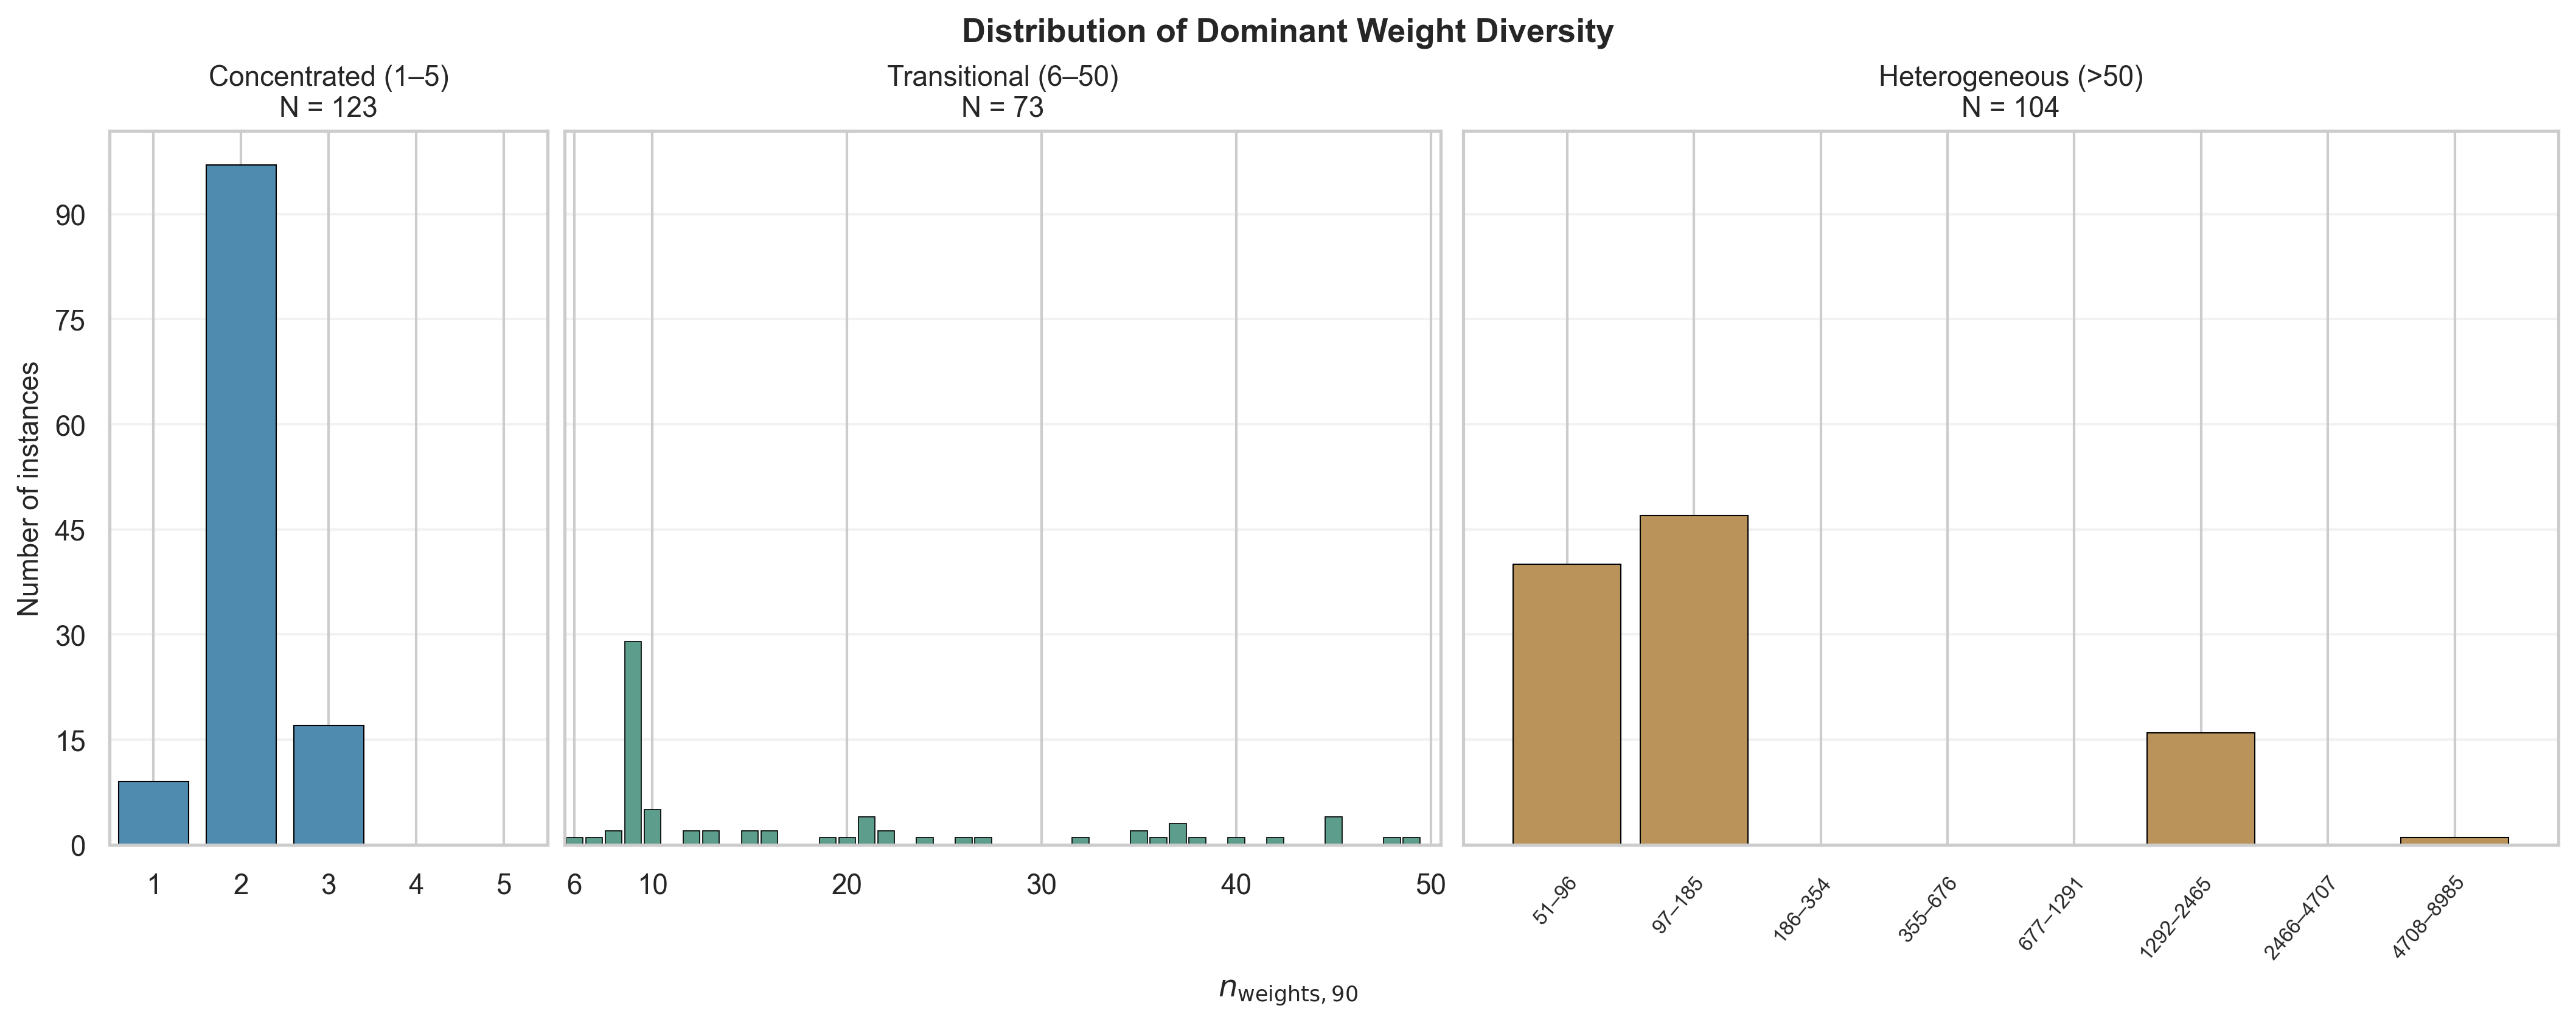

In [29]:
plotting.plot_n_weights_90_histogram(
    df_int,
    file_name="n_weights_90_histogram.pdf"
)

In [30]:
df_int[df_int['concentration_group']=='Uniform']['size_cat'].value_counts()

size_cat
large     27
medium    22
Name: count, dtype: int64

In [31]:
df_int[df_int['concentration_group']=='Concentrated']['size_cat'].value_counts()

size_cat
medium    67
large     56
Name: count, dtype: int64

In [32]:
df_int[df_int['concentration_group']=='Transitional']['size_cat'].value_counts()

size_cat
medium    54
large     19
Name: count, dtype: int64

In [33]:
df_int[df_int['concentration_group']=='Heterogeneous']['size_cat'].value_counts()

size_cat
medium    74
large     30
Name: count, dtype: int64

In [34]:
results = []

solvers = cfg.SOLVERS

for category, group in df_int.groupby("concentration_group"):

    n = len(group)

    row = {
        "concentration_group": category,
        "n": n
    }

    for solver in solvers:

        
        hits = np.isclose(
            group[solver].to_numpy(dtype=float),
            group["baseline_objective"].to_numpy(dtype=float),
            atol=1e-9,
            rtol=0
        ).sum()


        pct_hits = (hits / n) * 100

        row[solver] = pct_hits

    results.append(row)

summary_df = pd.DataFrame(results)

summary_df["concentration_group"] = pd.Categorical(
    summary_df["concentration_group"],
    categories=cfg.CATEGORY_ORDER_UW,
    ordered=True
)

summary_df = summary_df.sort_values(
    "concentration_group"
).reset_index(drop=True)

summary_df

,concentration_group,n,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
0,Uniform,49,38.775510,100.000000,59.183673,40.816327,32.653061,26.530612,46.938776
1,Concentrated,123,52.845528,96.747967,30.894309,25.203252,25.203252,21.138211,20.325203
2,Transitional,73,47.945205,60.273973,19.178082,13.698630,13.698630,19.178082,26.027397
3,Heterogeneous,104,43.269231,74.038462,31.730769,23.076923,1.923077,4.807692,42.307692


In [35]:
from statsmodels.stats.proportion import proportion_confint

results = []

for category, group in df_int.groupby("concentration_group"):

    n = len(group)

    row = {
        "concentration_group": category,
        "n": n
    }

    for solver in solvers:

        successes = (group[solver] == group["baseline_objective"]).sum()
        proportion = successes / n

        ci_low, ci_high = proportion_confint(
            successes,
            n,
            alpha=0.05,
            method="wilson"
        )

        row[f"{solver}_pct"] = proportion * 100
        row[f"{solver}_ci_low"] = ci_low * 100
        row[f"{solver}_ci_high"] = ci_high * 100


    results.append(row)

ci_table = pd.DataFrame(results)

ci_table["concentration_group"] = pd.Categorical(
    summary_df["concentration_group"],
    categories=cfg.CATEGORY_ORDER_UW,
    ordered=True
)

ci_table = ci_table.sort_values(
    "concentration_group"
).reset_index(drop=True)

ci_table

,concentration_group,n,DAv2_pct,DAv2_ci_low,DAv2_ci_high,DAv3_pct,DAv3_ci_low,DAv3_ci_high,DAv3c_pct,DAv3c_ci_low,...,heuristic_ci_high,BURER2002_pct,BURER2002_ci_low,BURER2002_ci_high,MERZ1999GLS_pct,MERZ1999GLS_ci_low,MERZ1999GLS_ci_high,PAL2004bMTS2_pct,PAL2004bMTS2_ci_low,PAL2004bMTS2_ci_high
0,Uniform,123,52.845528,44.071658,61.447042,96.747967,91.936138,98.728224,30.894309,23.411077,...,33.547379,25.203252,18.361090,33.547379,21.138211,14.853401,29.171210,20.325203,14.163307,28.284532
1,Concentrated,104,43.269231,34.155001,52.862979,74.038462,64.863352,81.501006,31.730769,23.573154,...,32.045512,1.923077,0.528971,6.742313,4.807692,2.070804,10.764203,42.307692,33.253214,51.910191
2,Transitional,73,47.945205,36.877454,59.218403,60.273973,48.807414,70.713298,19.178082,11.782361,...,23.412427,13.698630,7.614390,23.412427,19.178082,11.782361,29.655503,26.027397,17.342183,37.109488
3,Heterogeneous,49,38.775510,26.429012,52.754001,100.000000,92.730218,100.000000,59.183673,45.247319,...,54.752681,32.653061,21.207497,46.620795,26.530612,16.211282,40.262289,46.938776,33.703504,60.619136


In [36]:
dav3_vs_pal = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3",
    solver_b="PAL2004bMTS2"
)
dav3_vs_pal

,category,n,DAv3_wins,ties,PAL2004bMTS2_wins,DAv3_win_pct,tie_pct,PAL2004bMTS2_win_pct
0,Concentrated,123,98,25,0,79.674797,20.325203,0.000000
1,Heterogeneous,104,52,32,20,50.000000,30.769231,19.230769
2,Transitional,73,48,11,14,65.753425,15.068493,19.178082
3,Uniform,49,26,23,0,53.061224,46.938776,0.000000


In [37]:
dav2_vs_pal = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv2",
    solver_b="PAL2004bMTS2"
)
dav2_vs_pal

,category,n,DAv2_wins,ties,PAL2004bMTS2_wins,DAv2_win_pct,tie_pct,PAL2004bMTS2_win_pct
0,Concentrated,123,98,23,2,79.674797,18.699187,1.626016
1,Heterogeneous,104,48,12,44,46.153846,11.538462,42.307692
2,Transitional,73,48,9,16,65.753425,12.328767,21.917808
3,Uniform,49,24,14,11,48.979592,28.571429,22.448980


In [38]:
dav3c_vs_pal = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3c",
    solver_b="PAL2004bMTS2"
)
dav3c_vs_pal

,category,n,DAv3c_wins,ties,PAL2004bMTS2_wins,DAv3c_win_pct,tie_pct,PAL2004bMTS2_win_pct
0,Concentrated,123,93,24,6,75.609756,19.512195,4.878049
1,Heterogeneous,104,25,29,50,24.038462,27.884615,48.076923
2,Transitional,73,28,11,34,38.356164,15.068493,46.575342
3,Uniform,49,18,22,9,36.734694,44.897959,18.367347


In [39]:
dav3_vs_merz = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3",
    solver_b="MERZ1999GLS"
)
dav3_vs_merz

,category,n,DAv3_wins,ties,MERZ1999GLS_wins,DAv3_win_pct,tie_pct,MERZ1999GLS_win_pct
0,Concentrated,123,97,26,0,78.861789,21.138211,0.000000
1,Heterogeneous,104,81,5,18,77.884615,4.807692,17.307692
2,Transitional,73,52,10,11,71.232877,13.698630,15.068493
3,Uniform,49,36,13,0,73.469388,26.530612,0.000000


In [40]:
dav2_vs_merz = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv2",
    solver_b="MERZ1999GLS"
)
dav2_vs_merz

,category,n,DAv2_wins,ties,MERZ1999GLS_wins,DAv2_win_pct,tie_pct,MERZ1999GLS_win_pct
0,Concentrated,123,96,23,4,78.048780,18.699187,3.252033
1,Heterogeneous,104,93,2,9,89.423077,1.923077,8.653846
2,Transitional,73,51,9,13,69.863014,12.328767,17.808219
3,Uniform,49,32,6,11,65.306122,12.244898,22.448980


In [41]:
dav3c_vs_merz = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3c",
    solver_b="MERZ1999GLS"
)
dav3c_vs_merz

,category,n,DAv3c_wins,ties,MERZ1999GLS_wins,DAv3c_win_pct,tie_pct,MERZ1999GLS_win_pct
0,Concentrated,123,97,26,0,78.861789,21.138211,0.000000
1,Heterogeneous,104,68,6,30,65.384615,5.769231,28.846154
2,Transitional,73,38,10,25,52.054795,13.698630,34.246575
3,Uniform,49,35,13,1,71.428571,26.530612,2.040816


In [42]:
dav3c_vs_burer = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3c",
    solver_b="BURER2002"
)
dav3c_vs_burer

,category,n,DAv3c_wins,ties,BURER2002_wins,DAv3c_win_pct,tie_pct,BURER2002_win_pct
0,Concentrated,123,60,29,34,48.780488,23.577236,27.642276
1,Heterogeneous,104,68,1,35,65.384615,0.961538,33.653846
2,Transitional,73,40,10,23,54.794521,13.698630,31.506849
3,Uniform,49,30,16,3,61.224490,32.653061,6.122449


In [43]:
dav3_vs_burer = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3",
    solver_b="BURER2002"
)
dav3_vs_burer

,category,n,DAv3_wins,ties,BURER2002_wins,DAv3_win_pct,tie_pct,BURER2002_win_pct
0,Concentrated,123,92,31,0,74.796748,25.203252,0.000000
1,Heterogeneous,104,85,2,17,81.730769,1.923077,16.346154
2,Transitional,73,62,10,1,84.931507,13.698630,1.369863
3,Uniform,49,33,16,0,67.346939,32.653061,0.000000


In [44]:
dav2_vs_burer = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv2",
    solver_b="BURER2002"
)
dav2_vs_burer

,category,n,DAv2_wins,ties,BURER2002_wins,DAv2_win_pct,tie_pct,BURER2002_win_pct
0,Concentrated,123,89,30,4,72.357724,24.390244,3.252033
1,Heterogeneous,104,100,1,3,96.153846,0.961538,2.884615
2,Transitional,73,53,9,11,72.602740,12.328767,15.068493
3,Uniform,49,26,12,11,53.061224,24.489796,22.448980


In [45]:
dav3_vs_dav3c = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3",
    solver_b="DAv3c"
)
dav3_vs_dav3c

,category,n,DAv3_wins,ties,DAv3c_wins,DAv3_win_pct,tie_pct,DAv3c_win_pct
0,Concentrated,123,84,38,1,68.292683,30.894309,0.813008
1,Heterogeneous,104,54,33,17,51.923077,31.730769,16.346154
2,Transitional,73,53,12,8,72.602740,16.438356,10.958904
3,Uniform,49,20,29,0,40.816327,59.183673,0.000000


In [46]:
dav3_vs_dav2 = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv3",
    solver_b="DAv2"
)
dav3_vs_dav2 

,category,n,DAv3_wins,ties,DAv2_wins,DAv3_win_pct,tie_pct,DAv2_win_pct
0,Concentrated,123,58,61,4,47.154472,49.593496,3.252033
1,Heterogeneous,104,48,29,27,46.153846,27.884615,25.961538
2,Transitional,73,35,20,18,47.945205,27.397260,24.657534
3,Uniform,49,30,19,0,61.224490,38.775510,0.000000


In [47]:
dav2_vs_dav3c = utils.pairwise_win_tie_loss_by_weight_category(
    df_int,
    solver_a="DAv2",
    solver_b="DAv3c"
)
dav2_vs_dav3c

,category,n,DAv2_wins,ties,DAv3c_wins,DAv2_win_pct,tie_pct,DAv3c_win_pct
0,Concentrated,123,84,33,6,68.292683,26.829268,4.878049
1,Heterogeneous,104,68,11,25,65.384615,10.576923,24.038462
2,Transitional,73,48,11,14,65.753425,15.068493,19.178082
3,Uniform,49,20,14,15,40.816327,28.571429,30.612245


In [48]:
results = []

for category, group in df_int.groupby("concentration_group"):

    n = len(group)

    row = {
        "concentration_group": category,
        "n": n
    }

    for solver in cfg.SOLVERS:
        
        hits = np.isclose(
            group[solver].to_numpy(dtype=float),
            group["baseline_objective"].to_numpy(dtype=float),
            atol=1e-9,
            rtol=0
        ).sum()


        pct_hits = (hits / n) * 100

        row[solver] = pct_hits

    results.append(row)

summary_df = pd.DataFrame(results)

summary_df["concentration_group"] = pd.Categorical(
    summary_df["concentration_group"],
    categories=cfg.CATEGORY_ORDER_UW,
    ordered=True
)

summary_df = summary_df.sort_values(
    "concentration_group"
).reset_index(drop=True)

summary_df

,concentration_group,n,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
0,Uniform,49,38.775510,100.000000,59.183673,40.816327,32.653061,26.530612,46.938776
1,Concentrated,123,52.845528,96.747967,30.894309,25.203252,25.203252,21.138211,20.325203
2,Transitional,73,47.945205,60.273973,19.178082,13.698630,13.698630,19.178082,26.027397
3,Heterogeneous,104,43.269231,74.038462,31.730769,23.076923,1.923077,4.807692,42.307692


In [49]:
from statsmodels.stats.proportion import proportion_confint

results = []

for category, group in df_int.groupby("concentration_group"):

    n = len(group)

    row = {
        "concentration_group": category,
        "n": n
    }

    for solver in cfg.SOLVERS:

        successes = (group[solver] == group["baseline_objective"]).sum()
        proportion = successes / n

        ci_low, ci_high = proportion_confint(
            successes,
            n,
            alpha=0.05,
            method="wilson"
        )

        row[f"{solver}_pct"] = proportion * 100
        row[f"{solver}_ci_low"] = ci_low * 100
        row[f"{solver}_ci_high"] = ci_high * 100


    results.append(row)

ci_table = pd.DataFrame(results)

ci_table["concentration_group"] = pd.Categorical(
    summary_df["concentration_group"],
    categories=cfg.CATEGORY_ORDER_UW,
    ordered=True
)

ci_table = ci_table.sort_values(
    "concentration_group"
).reset_index(drop=True)

ci_table

,concentration_group,n,DAv2_pct,DAv2_ci_low,DAv2_ci_high,DAv3_pct,DAv3_ci_low,DAv3_ci_high,DAv3c_pct,DAv3c_ci_low,...,heuristic_ci_high,BURER2002_pct,BURER2002_ci_low,BURER2002_ci_high,MERZ1999GLS_pct,MERZ1999GLS_ci_low,MERZ1999GLS_ci_high,PAL2004bMTS2_pct,PAL2004bMTS2_ci_low,PAL2004bMTS2_ci_high
0,Uniform,123,52.845528,44.071658,61.447042,96.747967,91.936138,98.728224,30.894309,23.411077,...,33.547379,25.203252,18.361090,33.547379,21.138211,14.853401,29.171210,20.325203,14.163307,28.284532
1,Concentrated,104,43.269231,34.155001,52.862979,74.038462,64.863352,81.501006,31.730769,23.573154,...,32.045512,1.923077,0.528971,6.742313,4.807692,2.070804,10.764203,42.307692,33.253214,51.910191
2,Transitional,73,47.945205,36.877454,59.218403,60.273973,48.807414,70.713298,19.178082,11.782361,...,23.412427,13.698630,7.614390,23.412427,19.178082,11.782361,29.655503,26.027397,17.342183,37.109488
3,Heterogeneous,49,38.775510,26.429012,52.754001,100.000000,92.730218,100.000000,59.183673,45.247319,...,54.752681,32.653061,21.207497,46.620795,26.530612,16.211282,40.262289,46.938776,33.703504,60.619136


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.proportion import proportion_confint

METRICS_PATH = (
    cfg.PROCESSED_DIR /
    "graph_weight_concentration_metrics.parquet"
)

df_metrics = pd.read_parquet(METRICS_PATH)

# Six solvers used in the concentration experiment
SOLVERS_R08 = cfg.SOLVERS

# Start from the existing integer-weighted subset
df_r08 = df_int.copy()

metric_columns = [
    "name", "r", "n80", "n85", "n90", "n95",
    "unique_ratio", "singleton_edge_fraction"
]

# Avoid duplicate columns when merging
df_r08 = df_r08.drop(
    columns=[
        c for c in metric_columns
        if c != "name" and c in df_r08.columns
    ],
    errors="ignore"
)

df_r08 = df_r08.merge(
    df_metrics[metric_columns],
    on="name",
    how="left",
    validate="one_to_one"
)

assert len(df_r08) == 349
assert df_r08["name"].is_unique
assert df_r08[["n80", "n85", "n90", "n95"]].notna().all().all()

# Check that all solver results are available
assert df_r08[SOLVERS_R08].notna().all().all()

print("R08 instances:", len(df_r08))
print("Solvers:", SOLVERS_R08)

R08 instances: 349
Solvers: ['DAv2', 'DAv3', 'DAv3c', 'heuristic', 'BURER2002', 'MERZ1999GLS', 'PAL2004bMTS2']


In [68]:
df_r08["best_of_six"] = df_r08[SOLVERS_R08].max(axis=1)

if "baseline_objective" in df_r08.columns:
    changed = ~np.isclose(
        df_r08["best_of_six"],
        df_r08["baseline_objective"],
        rtol=0,
        atol=1e-9
    )

    print("Differences from stored baseline_objective:",
          changed.sum())

    display(
        df_r08.loc[
            changed,
            ["name", "baseline_objective", "best_of_six"]
        ].head(20)
    )

Differences from stored baseline_objective: 0


,name,baseline_objective,best_of_six


In [69]:
CATEGORY_ORDER = [
    "Uniform",
    "Concentrated",
    "Transitional",
    "Heterogeneous"
]

THRESHOLDS = ["n80", "n85", "n90", "n95"]

def classify_concentration(r, n_q):
    if r == 1:
        return "Uniform"
    elif n_q <= 5:
        return "Concentrated"
    elif n_q <= 50:
        return "Transitional"
    else:
        return "Heterogeneous"


for metric in THRESHOLDS:
    col = f"group_{metric}"

    df_r08[col] = [
        classify_concentration(r, nq)
        for r, nq in zip(df_r08["r"], df_r08[metric])
    ]

    df_r08[col] = pd.Categorical(
        df_r08[col],
        categories=CATEGORY_ORDER,
        ordered=True
    )

# Category counts under each threshold
category_counts = pd.DataFrame({
    metric: (
        df_r08[f"group_{metric}"]
        .value_counts()
        .reindex(CATEGORY_ORDER, fill_value=0)
    )
    for metric in THRESHOLDS
})

display(category_counts)

,n80,n85,n90,n95
Uniform,49,49,49,49
Concentrated,126,124,123,123
Transitional,84,75,73,71
Heterogeneous,90,101,104,106


In [70]:
assert category_counts["n90"].tolist() == [49, 123, 73, 104]

# Mathematical monotonicity
assert (df_r08["n80"] <= df_r08["n85"]).all()
assert (df_r08["n85"] <= df_r08["n90"]).all()
assert (df_r08["n90"] <= df_r08["n95"]).all()
assert (df_r08["n95"] <= df_r08["r"]).all()

In [71]:
stability_rows = []

for metric in ["n80", "n85", "n95"]:
    same = (
        df_r08[f"group_{metric}"].astype(str)
        == df_r08["group_n90"].astype(str)
    )

    stability_rows.append({
        "metric": metric,
        "unchanged_instances": int(same.sum()),
        "changed_instances": int((~same).sum()),
        "unchanged_pct": 100 * same.mean()
    })

stability_summary = pd.DataFrame(stability_rows)

display(stability_summary.round(2))

,metric,unchanged_instances,changed_instances,unchanged_pct
0,n80,332,17,95.13
1,n85,345,4,98.85
2,n95,347,2,99.43


In [72]:
for metric in ["n80", "n85", "n95"]:
    print(f"\nN90 categories vs {metric.upper()} categories")

    transition = pd.crosstab(
        df_r08["group_n90"],
        df_r08[f"group_{metric}"],
        dropna=False
    )

    display(transition)


N90 categories vs N80 categories


group_n80,Uniform,Concentrated,Transitional,Heterogeneous
group_n90,,,,
Uniform,49,0,0,0
Concentrated,0,123,0,0
Transitional,0,3,70,0
Heterogeneous,0,0,14,90



N90 categories vs N85 categories


group_n85,Uniform,Concentrated,Transitional,Heterogeneous
group_n90,,,,
Uniform,49,0,0,0
Concentrated,0,123,0,0
Transitional,0,1,72,0
Heterogeneous,0,0,3,101



N90 categories vs N95 categories


group_n95,Uniform,Concentrated,Transitional,Heterogeneous
group_n90,,,,
Uniform,49,0,0,0
Concentrated,0,123,0,0
Transitional,0,0,71,2
Heterogeneous,0,0,0,104


In [73]:
TOL = 1e-9

success_records = []

for metric in THRESHOLDS:
    group_col = f"group_{metric}"

    for category, group in df_r08.groupby(
        group_col, observed=True
    ):
        n = len(group)

        for solver in SOLVERS_R08:
            hits = np.isclose(
                group[solver].to_numpy(dtype=float),
                group["best_of_six"].to_numpy(dtype=float),
                atol=TOL,
                rtol=0
            )

            k = int(hits.sum())

            ci_low, ci_high = proportion_confint(
                k, n, alpha=0.05, method="wilson"
            )

            success_records.append({
                "metric": metric,
                "category": str(category),
                "solver": solver,
                "n": n,
                "successes": k,
                "success_pct": 100 * k / n,
                "ci_low": 100 * ci_low,
                "ci_high": 100 * ci_high
            })

df_sensitivity = pd.DataFrame(success_records)

display(df_sensitivity.head())

,metric,category,solver,n,successes,success_pct,ci_low,ci_high
0,n80,Uniform,DAv2,49,19,38.775510,26.429012,52.754001
1,n80,Uniform,DAv3,49,49,100.000000,92.730218,100.000000
2,n80,Uniform,DAv3c,49,29,59.183673,45.247319,71.784761
3,n80,Uniform,heuristic,49,20,40.816327,28.215239,54.752681
4,n80,Uniform,BURER2002,49,16,32.653061,21.207497,46.620795


In [74]:
for metric in THRESHOLDS:
    print(f"\nSUCCESS RATES — {metric.upper()}")

    subset = df_sensitivity[
        df_sensitivity["metric"] == metric
    ]

    rates = subset.pivot(
        index="category",
        columns="solver",
        values="success_pct"
    ).reindex(CATEGORY_ORDER)

    display(rates[SOLVERS_R08].round(2))


SUCCESS RATES — N80


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
category,,,,,,,
Uniform,38.78,100.00,59.18,40.82,32.65,26.53,46.94
Concentrated,52.38,94.44,30.16,24.60,24.60,21.43,20.63
Transitional,42.86,66.67,16.67,11.90,11.90,15.48,23.81
Heterogeneous,47.78,72.22,36.67,26.67,2.22,5.56,46.67



SUCCESS RATES — N85


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
category,,,,,,,
Uniform,38.78,100.00,59.18,40.82,32.65,26.53,46.94
Concentrated,53.23,95.97,30.65,25.00,25.00,20.97,20.16
Transitional,45.33,60.00,18.67,13.33,13.33,18.67,28.00
Heterogeneous,44.55,75.25,32.67,23.76,1.98,4.95,41.58



SUCCESS RATES — N90


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
category,,,,,,,
Uniform,38.78,100.00,59.18,40.82,32.65,26.53,46.94
Concentrated,52.85,96.75,30.89,25.20,25.20,21.14,20.33
Transitional,47.95,60.27,19.18,13.70,13.70,19.18,26.03
Heterogeneous,43.27,74.04,31.73,23.08,1.92,4.81,42.31



SUCCESS RATES — N95


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
category,,,,,,,
Uniform,38.78,100.00,59.18,40.82,32.65,26.53,46.94
Concentrated,52.85,96.75,30.89,25.20,25.20,21.14,20.33
Transitional,49.30,61.97,19.72,14.08,14.08,19.72,23.94
Heterogeneous,42.45,72.64,31.13,22.64,1.89,4.72,43.40


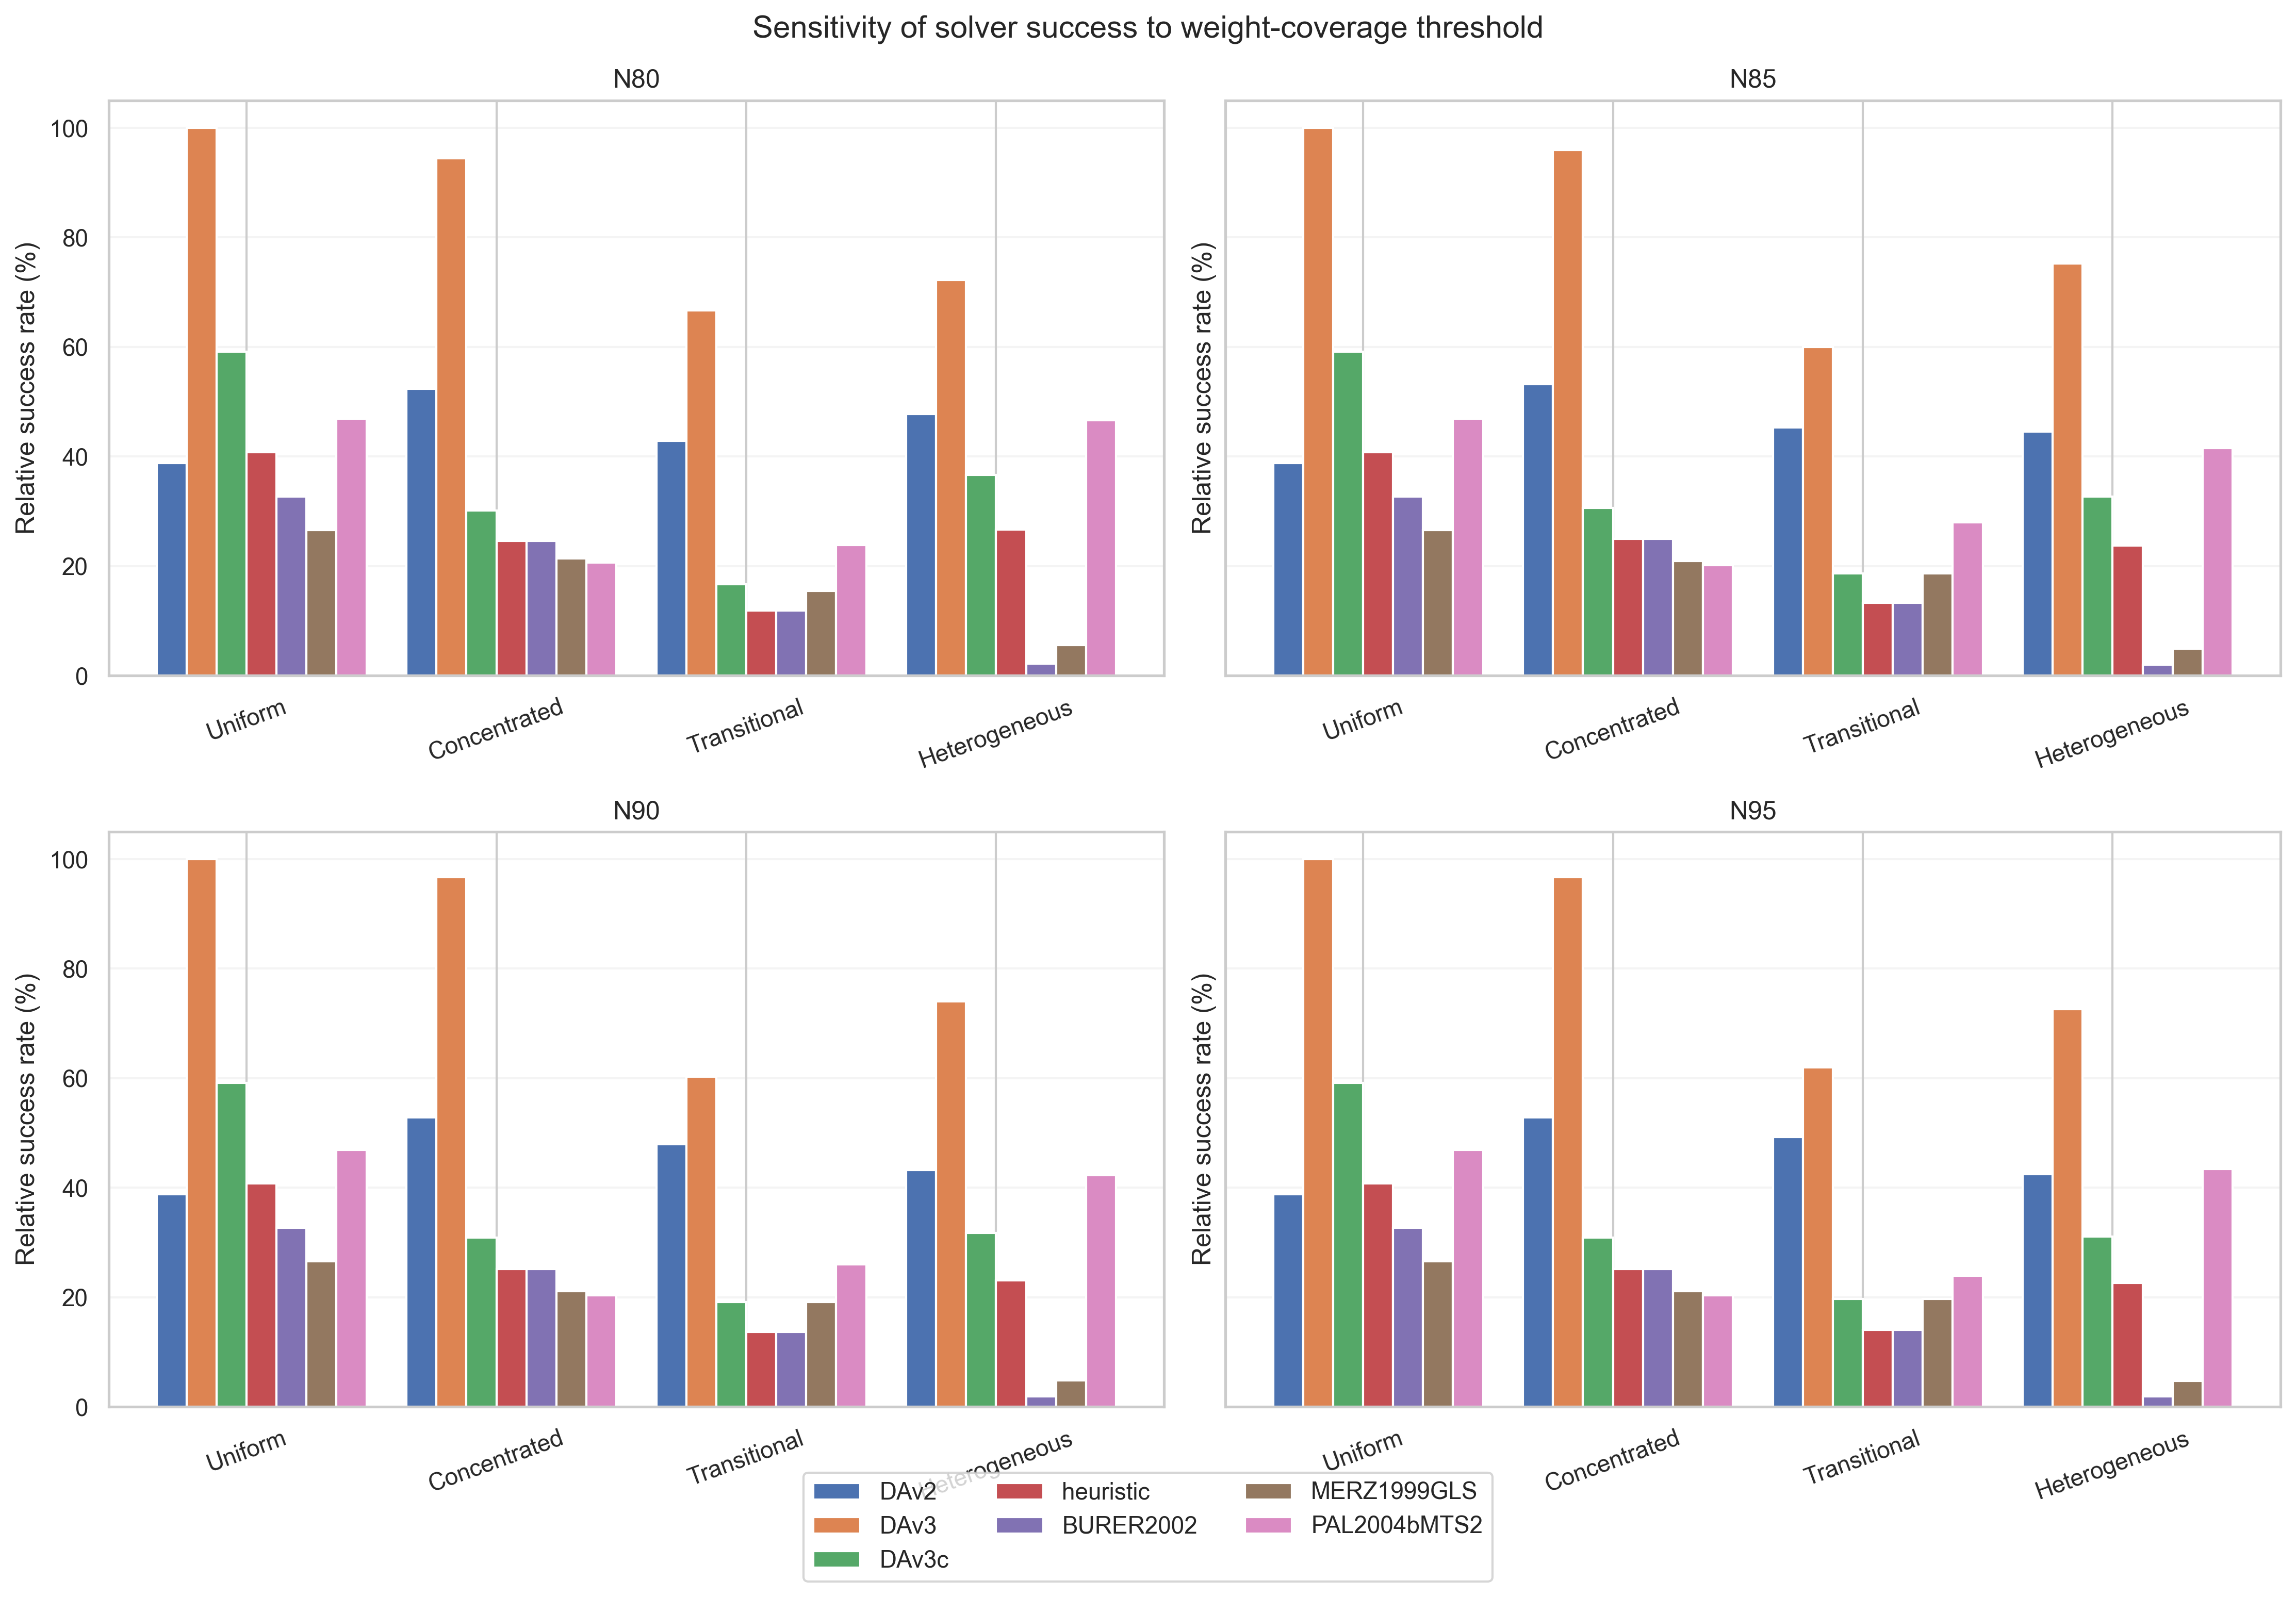

In [75]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
    sharey=True
)

axes = axes.flatten()

for ax, metric in zip(axes, THRESHOLDS):
    subset = df_sensitivity[
        df_sensitivity["metric"] == metric
    ]

    rates = subset.pivot(
        index="category",
        columns="solver",
        values="success_pct"
    ).reindex(CATEGORY_ORDER)

    x = np.arange(len(CATEGORY_ORDER))
    width = 0.12

    for i, solver in enumerate(SOLVERS_R08):
        ax.bar(
            x + (i - 2.5) * width,
            rates[solver],
            width,
            label=solver
        )

    ax.set_title(metric.upper())
    ax.set_xticks(x)
    ax.set_xticklabels(
        CATEGORY_ORDER,
        rotation=20
    )
    ax.set_ylim(0, 105)
    ax.set_ylabel("Relative success rate (%)")
    ax.grid(axis="y", alpha=0.2)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.04)
)

fig.suptitle(
    "Sensitivity of solver success to weight-coverage threshold"
)

plt.tight_layout()
plt.show()

In [76]:
# Compare category membership with N90
for metric in ["n80", "n85", "n95"]:

    print(f"\nN90 vs {metric.upper()}")

    transition = pd.crosstab(
        df_r08["group_n90"],
        df_r08[f"group_{metric}"]
    ).reindex(
        index=CATEGORY_ORDER,
        columns=CATEGORY_ORDER,
        fill_value=0
    )

    display(transition)

    unchanged = sum(
        df_r08["group_n90"].astype(str)
        == df_r08[f"group_{metric}"].astype(str)
    )

    print(
        f"Unchanged: {unchanged}/349 "
        f"({100 * unchanged / 349:.2f}%)"
    )


N90 vs N80


group_n80,Uniform,Concentrated,Transitional,Heterogeneous
group_n90,,,,
Uniform,49,0,0,0
Concentrated,0,123,0,0
Transitional,0,3,70,0
Heterogeneous,0,0,14,90


Unchanged: 332/349 (95.13%)

N90 vs N85


group_n85,Uniform,Concentrated,Transitional,Heterogeneous
group_n90,,,,
Uniform,49,0,0,0
Concentrated,0,123,0,0
Transitional,0,1,72,0
Heterogeneous,0,0,3,101


Unchanged: 345/349 (98.85%)

N90 vs N95


group_n95,Uniform,Concentrated,Transitional,Heterogeneous
group_n90,,,,
Uniform,49,0,0,0
Concentrated,0,123,0,0
Transitional,0,0,71,2
Heterogeneous,0,0,0,104


Unchanged: 347/349 (99.43%)


In [77]:
composition = (
    df_r08.groupby("group_n90", observed=True)
    .agg(
        N=("name", "size"),
        median_nodes=("nodes", "median"),
        median_edges=("edges", "median"),
        median_density=("density", "median"),
        median_TL=("limit", "median"),
        median_unique_weights=("r", "median"),
        median_n90=("n90", "median")
    )
    .reindex(CATEGORY_ORDER)
)

display(composition.round(4))

print("Size-density composition:")

display(
    pd.crosstab(
        df_r08["group_n90"],
        [
            df_r08["size_cat"],
            df_r08["density_cat"]
        ]
    )
)

,N,median_nodes,median_edges,median_density,median_TL,median_unique_weights,median_n90
group_n90,,,,,,,
Uniform,49,4157.0,698044.0,0.1010,39.048,1.0,1.0
Concentrated,123,3983.0,14000.0,0.0022,14.605,2.0,2.0
Transitional,73,2521.0,11502.0,0.0029,9.229,25.0,10.0
Heterogeneous,104,3001.0,310233.5,0.0993,23.485,200.0,180.0


Size-density composition:


size_cat         large                medium             
density_cat   balanced dense sparse balanced dense sparse
group_n90                                                
Uniform             15     4      8        4     2     16
Concentrated        12     4     40        8     5     54
Transitional         4     1     14        3     3     48
Heterogeneous       12     9      9        8    13     53

In [78]:
print("N90 category counts:")
display(df_r08["group_n90"].value_counts())

print("Current best-of-six reference:")
display(
    df_r08[
        ["name", "group_n90", "DAv3", "best_of_six"]
    ].head()
)

print("DAv3 N90 successes:")
for category, group in df_r08.groupby(
    "group_n90", observed=True
):
    successes = np.isclose(
        group["DAv3"],
        group["best_of_six"],
        atol=1e-9,
        rtol=0
    ).sum()

    print(category, successes, "/", len(group))

N90 category counts:


group_n90
Concentrated     123
Heterogeneous    104
Transitional      73
Uniform           49
Name: count, dtype: int64

Current best-of-six reference:


,name,group_n90,DAv3,best_of_six
0,G55,Uniform,10294.0,10294.0
1,G56,Concentrated,4015.0,4015.0
2,G57,Concentrated,3480.0,3480.0
3,G58,Uniform,19269.0,19269.0
4,G59,Concentrated,6077.0,6077.0


DAv3 N90 successes:
Uniform 49 / 49
Concentrated 119 / 123
Transitional 44 / 73
Heterogeneous 77 / 104


In [79]:
from statsmodels.stats.proportion import proportion_confint
import numpy as np
import pandas as pd

df_controlled = df_r08.copy()

df_controlled["size_density"] = (
    df_controlled["size_cat"].astype(str)
    + "_"
    + df_controlled["density_cat"].astype(str)
)

records = []

for (size_density, concentration), group in df_controlled.groupby(
    ["size_density", "group_n90"],
    observed=True
):
    n = len(group)

    for solver in SOLVERS_R08:
        successes = np.isclose(
            group[solver].to_numpy(dtype=float),
            group["best_of_six"].to_numpy(dtype=float),
            atol=1e-9,
            rtol=0
        )

        k = int(successes.sum())

        low, high = proportion_confint(
            k, n,
            alpha=0.05,
            method="wilson"
        )

        records.append({
            "size_density": size_density,
            "concentration": str(concentration),
            "solver": solver,
            "N": n,
            "successes": k,
            "success_pct": 100 * k / n,
            "ci_low": 100 * low,
            "ci_high": 100 * high
        })

df_controlled_results = pd.DataFrame(records)

# Display the group sizes
display(
    df_controlled_results[
        df_controlled_results["solver"] == "DAv3"
    ].pivot(
        index="size_density",
        columns="concentration",
        values="N"
    ).reindex(columns=CATEGORY_ORDER)
)

# DAv3 success rates
display(
    df_controlled_results[
        df_controlled_results["solver"] == "DAv3"
    ].pivot(
        index="size_density",
        columns="concentration",
        values="success_pct"
    ).reindex(columns=CATEGORY_ORDER).round(2)
)

concentration,Uniform,Concentrated,Transitional,Heterogeneous
size_density,,,,
large_balanced,15,12,4,12
large_dense,4,4,1,9
large_sparse,8,40,14,9
medium_balanced,4,8,3,8
medium_dense,2,5,3,13
medium_sparse,16,54,48,53


concentration,Uniform,Concentrated,Transitional,Heterogeneous
size_density,,,,
large_balanced,100.0,100.00,100.00,91.67
large_dense,100.0,100.00,100.00,88.89
large_sparse,100.0,97.50,64.29,88.89
medium_balanced,100.0,100.00,100.00,100.00
medium_dense,100.0,100.00,100.00,92.31
medium_sparse,100.0,94.44,50.00,56.60


In [80]:
for category in sorted(
    df_controlled_results["size_density"].unique()
):
    sub = df_controlled_results[
        df_controlled_results["size_density"] == category
    ]

    print(f"\n{category.upper()}")

    table = sub.pivot(
        index="concentration",
        columns="solver",
        values="success_pct"
    )

    display(
        table.reindex(
            index=CATEGORY_ORDER,
            columns=SOLVERS_R08
        ).round(2)
    )

    print("Instance counts:")

    display(
        sub[sub["solver"] == "DAv3"][
            ["concentration", "N"]
        ].set_index("concentration")
        .reindex(CATEGORY_ORDER)
    )


LARGE_BALANCED


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
concentration,,,,,,,
Uniform,0.00,100.00,66.67,40.00,20.00,33.33,40.00
Concentrated,50.00,100.00,66.67,58.33,50.00,58.33,58.33
Transitional,0.00,100.00,25.00,25.00,25.00,25.00,25.00
Heterogeneous,8.33,91.67,33.33,33.33,8.33,8.33,33.33


Instance counts:


,N
concentration,
Uniform,15
Concentrated,12
Transitional,4
Heterogeneous,12



LARGE_DENSE


...

,N
concentration,
Uniform,2
Concentrated,5
Transitional,3
Heterogeneous,13



MEDIUM_SPARSE


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
concentration,,,,,,,
Uniform,81.25,100.00,87.50,62.50,62.50,25.00,81.25
Concentrated,53.70,94.44,20.37,18.52,18.52,5.56,7.41
Transitional,58.33,50.00,16.67,10.42,10.42,18.75,22.92
Heterogeneous,50.94,56.60,20.75,0.00,0.00,3.77,39.62


Instance counts:


,N
concentration,
Uniform,16
Concentrated,54
Transitional,48
Heterogeneous,53


In [81]:
composition_within = (
    df_controlled.groupby(
        ["size_density", "group_n90"],
        observed=True
    )
    .agg(
        N=("name", "size"),
        median_nodes=("nodes", "median"),
        median_density=("density", "median"),
        median_TL=("limit", "median")
    )
)

display(composition_within.round(5))

N  median_nodes  median_density  median_TL
size_density    group_n90                                                 
large_balanced  Uniform        15        5330.0         0.27821   198.5350
                Concentrated   12        6127.5         0.23836   120.1680
                Transitional    4        4932.0         0.36690   222.8350
                Heterogeneous  12        6009.0         0.39035   388.7665
large_dense     Uniform         4        5094.0         0.76918   297.8340
                Concentrated    4        5267.0         0.62428   155.9935
                Transitional    1        6348.0         0.58658   614.9250
                Heterogeneous   9        5001.0         0.79620   543.8810
large_sparse    Uniform         8        4984.5         0.00265    19.8305
                Concentrated   40        5265.0         0.00103    23.5725
                Transitional   14        4771.0         0.00092    19.1905
                Heterogeneous   9        7998.0         0.00046    39.8440
medium_balanced Uniform         4        3199.5         0.37820    45.2885
                Concentrated    8        3614.0         0.21769    42.3805
                Transitional    3        3184.0         0.30869    51.9420
                Heterogeneous   8        3000.5         0.46447    97.6285
medium_dense    Uniform         2        2812.0         0.64417    73.4320
                Concentrated    5        3360.0         0.79367    68.1220
                Transitional    3        3639.0         0.86266   179.3350
                Heterogeneous  13        3001.0         0.79617   168.7590
medium_sparse   Uniform        16        3000.0         0.00157     5.1105
                Concentrated   54        2959.0         0.00205     6.0875
                Transitional   48        2500.0         0.00172     4.7995
                Heterogeneous  53        2676.0         0.00178     9.9570

In [82]:
# Common size-density distribution among all 349 instances
stratum_weights = (
    df_r08.groupby(["size_cat", "density_cat"], observed=True)
    .size()
)

stratum_weights = stratum_weights / stratum_weights.sum()

# Per-instance success indicators
df_std = df_r08.copy()

for solver in SOLVERS_R08:
    df_std[f"success_{solver}"] = np.isclose(
        df_std[solver].to_numpy(dtype=float),
        df_std["best_of_six"].to_numpy(dtype=float),
        atol=1e-9,
        rtol=0
    ).astype(int)

records = []

for concentration in CATEGORY_ORDER:
    sub = df_std[
        df_std["group_n90"].astype(str) == concentration
    ]

    for solver in SOLVERS_R08:
        raw_success = sub[f"success_{solver}"].mean()

        # Success by size-density stratum
        stratum_success = (
            sub.groupby(
                ["size_cat", "density_cat"],
                observed=True
            )[f"success_{solver}"]
            .mean()
        )

        if not stratum_weights.index.isin(
            stratum_success.index
        ).all():
            raise ValueError(
                f"Missing size-density stratum in {concentration}"
            )

        # Direct standardization using common stratum weights
        adjusted_success = sum(
            weight * stratum_success.loc[stratum]
            for stratum, weight in stratum_weights.items()
        )

        records.append({
            "category": concentration,
            "solver": solver,
            "N": len(sub),
            "raw_success_pct": 100 * raw_success,
            "standardized_success_pct": 100 * adjusted_success
        })

df_standardized = pd.DataFrame(records)

for measure in [
    "raw_success_pct",
    "standardized_success_pct"
]:
    print(f"\n{measure}")

    display(
        df_standardized.pivot(
            index="category",
            columns="solver",
            values=measure
        )
        .reindex(index=CATEGORY_ORDER, columns=SOLVERS_R08)
        .round(2)
    )


raw_success_pct


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
category,,,,,,,
Uniform,38.78,100.00,59.18,40.82,32.65,26.53,46.94
Concentrated,52.85,96.75,30.89,25.20,25.20,21.14,20.33
Transitional,47.95,60.27,19.18,13.70,13.70,19.18,26.03
Heterogeneous,43.27,74.04,31.73,23.08,1.92,4.81,42.31



standardized_success_pct


solver,DAv2,DAv3,DAv3c,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
category,,,,,,,
Uniform,56.57,100.00,62.01,43.93,39.82,24.74,53.12
Concentrated,56.79,96.77,35.62,30.82,30.62,25.80,25.38
Transitional,40.98,68.24,19.26,14.74,14.74,18.82,25.22
Heterogeneous,40.08,74.37,25.07,17.60,3.29,4.52,34.75


In [87]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

df = df_int.copy()

# Six individual solvers.
# Exclude the aggregate "heuristic" column.
solvers = [
    "DAv2",
    "DAv3",
    "DAv3c",
    "BURER2002",
    "MERZ1999GLS",
    "PAL2004bMTS2"
]

group_order = [
    "Uniform",
    "Concentrated",
    "Transitional",
    "Heterogeneous"
]

size_order = ["medium", "large"]
density_order = ["sparse", "balanced", "dense"]

strata_order = [
    f"{size}_{density}"
    for size in size_order
    for density in density_order
]

required = [
    "name",
    "concentration_group",
    "size_cat",
    "density_cat"
] + solvers

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

assert df["name"].is_unique, "Duplicate instance names found."

for col in ["concentration_group", "size_cat", "density_cat"]:
    df[col] = df[col].astype(str).str.strip()

df = df[
    df["concentration_group"].isin(group_order)
    & df["size_cat"].isin(size_order)
    & df["density_cat"].isin(density_order)
].copy()

assert len(df) == 349, (
    f"Expected 349 instances, got {len(df)}"
)

assert df[solvers].notna().all().all(), (
    "Some instances have missing solver objectives."
)

# --------------------------------------------------
# 2. Check aggregate heuristic against individual
#    heuristic objectives (diagnostic only)
# --------------------------------------------------

individual_heuristics = [
    "BURER2002",
    "MERZ1999GLS",
    "PAL2004bMTS2"
]

if "heuristic" in df.columns:
    heuristic_max = df[individual_heuristics].max(axis=1)

    matches = np.isclose(
        df["heuristic"].to_numpy(dtype=float),
        heuristic_max.to_numpy(dtype=float),
        atol=1e-9,
        rtol=0
    )

    print(
        "Instances where aggregate heuristic differs "
        "from max of three heuristics:",
        (~matches).sum()
    )

    if not matches.all():
        display(
            df.loc[
                ~matches,
                ["name", "heuristic"] + individual_heuristics
            ]
        )

# --------------------------------------------------
# 3. Joint size-density composition
# --------------------------------------------------

df["stratum"] = (
    df["size_cat"] + "_" + df["density_cat"]
)

composition = (
    pd.crosstab(
        df["concentration_group"],
        df["stratum"]
    )
    .reindex(
        index=group_order,
        columns=strata_order,
        fill_value=0
    )
)

print("\nJoint size-density composition:")
display(composition)

# --------------------------------------------------
# 4. Calculate best-of-six success indicators
# --------------------------------------------------

objectives = df[solvers].to_numpy(dtype=float)

# Best objective among the six individual solvers
best_objective = objectives.max(axis=1)

df["best_objective_6"] = best_objective

for j, solver in enumerate(solvers):
    df[f"success_{solver}"] = np.isclose(
        objectives[:, j],
        best_objective,
        atol=1e-9,
        rtol=0
    ).astype(int)

# Ties count as successes for all tied solvers.

# --------------------------------------------------
# 5. Compare old four-solver and new six-solver
#    reference objectives
# --------------------------------------------------

old_four = [
    "DAv2",
    "DAv3",
    "DAv3c",
    "BURER2002"
]

best_four = df[old_four].max(axis=1).to_numpy()

changed = ~np.isclose(
    best_four,
    best_objective,
    atol=1e-9,
    rtol=0
)

print(
    "\nInstances where best-of-six differs "
    "from best-of-four:",
    changed.sum()
)

# Optional: inspect which instances changed
if changed.any():
    display(
        df.loc[
            changed,
            ["name", "concentration_group", "stratum"]
            + solvers
        ]
    )

# --------------------------------------------------
# 6. Common-support size-density strata
# --------------------------------------------------

common_strata = composition.columns[
    composition.gt(0).all(axis=0)
].tolist()

excluded_strata = [
    k for k in strata_order
    if k not in common_strata
]

print("\nCommon-support strata:", common_strata)
print("Excluded strata:", excluded_strata)

if not common_strata:
    raise ValueError(
        "No shared size-density strata across groups."
    )

df_common = df[
    df["stratum"].isin(common_strata)
].copy()

# Same reference distribution for every group
weights = (
    df_common["stratum"]
    .value_counts(normalize=True)
    .reindex(common_strata)
)

assert np.isclose(weights.sum(), 1.0)

print("\nStandardization weights (%):")
display((100 * weights).round(2))

# --------------------------------------------------
# 7. Pooled and standardized success rates
# --------------------------------------------------

rows = []

for solver in solvers:

    success_col = f"success_{solver}"

    # Pooled success across all 349 instances
    pooled = (
        df.groupby("concentration_group")[success_col]
        .mean()
        .reindex(group_order)
    )

    # Pooled success restricted to common support
    pooled_common = (
        df_common.groupby(
            "concentration_group"
        )[success_col]
        .mean()
        .reindex(group_order)
    )

    # Success within each size-density stratum
    stratum_rates = (
        df_common.groupby(
            ["concentration_group", "stratum"]
        )[success_col]
        .mean()
        .unstack("stratum")
        .reindex(
            index=group_order,
            columns=common_strata
        )
    )

    assert stratum_rates.notna().all().all(), (
        f"Missing stratum rates for {solver}"
    )

    # Direct standardization using common weights
    standardized = (
        stratum_rates
        .mul(weights, axis=1)
        .sum(axis=1)
    )

    for group in group_order:
        rows.append({
            "Solver": solver,
            "Concentration": group,
            "N_total": (
                df["concentration_group"] == group
            ).sum(),
            "N_common": (
                df_common["concentration_group"] == group
            ).sum(),
            "Pooled (%)": 100 * pooled.loc[group],
            "Pooled common (%)": (
                100 * pooled_common.loc[group]
            ),
            "Standardized (%)": (
                100 * standardized.loc[group]
            ),
            "Std - common pooled (pp)": 100 * (
                standardized.loc[group]
                - pooled_common.loc[group]
            )
        })

results = pd.DataFrame(rows)

print("\nSix-solver pooled and standardized success:")
display(results.round(2))

# --------------------------------------------------
# 8. Manuscript-ready table
# --------------------------------------------------

paper_table = results[
    [
        "Solver",
        "Concentration",
        "Pooled (%)",
        "Standardized (%)"
    ]
].copy()

print("\nManuscript-ready table:")
display(paper_table.round(2))

# Optional: one row per solver, grouped by
# concentration, with pooled / standardized rates

paper_table["Pooled / Std"] = paper_table.apply(
    lambda r: (
        f"{r['Pooled (%)']:.2f} / "
        f"{r['Standardized (%)']:.2f}"
    ),
    axis=1
)

paper_wide = paper_table.pivot(
    index="Solver",
    columns="Concentration",
    values="Pooled / Std"
)

paper_wide = paper_wide.reindex(
    index=solvers,
    columns=group_order
)

print("\nCompact manuscript table:")
display(paper_wide)

# --------------------------------------------------
# 9. Save
# --------------------------------------------------

results.to_csv(
    "edge_weight_concentration_standardization.csv",
    index=False
)


Instances where aggregate heuristic differs from max of three heuristics: 97


,name,heuristic,BURER2002,MERZ1999GLS,PAL2004bMTS2
3,G58,19092.0,19092.0,19122.0,19112.0
4,G59,5915.0,5915.0,5953.0,5940.0
8,G63,26756.0,26756.0,26822.0,26809.0
9,G64,8494.0,8494.0,8483.0,8565.0
48,be2500.10,1478763.0,1478763.0,1482756.0,1483355.0
...,...,...,...,...,...
3027,g003055,476944570.0,476944570.0,476951148.0,477821196.0
3045,g003073,455259846.0,455259846.0,456063416.0,457156574.0
3070,g003098,6302899.0,6302899.0,6296944.0,6304945.0
3140,g003170,327015581.0,327015581.0,327016081.0,327016047.0



Joint size-density composition:


stratum,medium_sparse,medium_balanced,medium_dense,large_sparse,large_balanced,large_dense
concentration_group,,,,,,
Uniform,16,4,2,8,15,4
Concentrated,54,8,5,40,12,4
Transitional,48,3,3,14,4,1
Heterogeneous,53,8,13,9,12,9



Instances where best-of-six differs from best-of-four: 23


...

,Solver,Concentration,N_total,N_common,Pooled (%),Pooled common (%),Standardized (%),Std - common pooled (pp)
0,DAv2,Uniform,49,49,38.78,38.78,56.57,17.80
1,DAv2,Concentrated,123,123,52.85,52.85,56.79,3.95
2,DAv2,Transitional,73,73,47.95,47.95,40.98,-6.96
3,DAv2,Heterogeneous,104,104,43.27,43.27,40.08,-3.19
4,DAv3,Uniform,49,49,100.00,100.00,100.00,0.00
5,DAv3,Concentrated,123,123,96.75,96.75,96.77,0.02
6,DAv3,Transitional,73,73,60.27,60.27,68.24,7.96
7,DAv3,Heterogeneous,104,104,74.04,74.04,74.37,0.33
8,DAv3c,Uniform,49,49,59.18,59.18,62.01,2.83
9,DAv3c,Concentrated,123,123,30.89,30.89,35.62,4.72



Manuscript-ready table:


,Solver,Concentration,Pooled (%),Standardized (%)
0,DAv2,Uniform,38.78,56.57
1,DAv2,Concentrated,52.85,56.79
2,DAv2,Transitional,47.95,40.98
3,DAv2,Heterogeneous,43.27,40.08
4,DAv3,Uniform,100.00,100.00
5,DAv3,Concentrated,96.75,96.77
6,DAv3,Transitional,60.27,68.24
7,DAv3,Heterogeneous,74.04,74.37
8,DAv3c,Uniform,59.18,62.01
9,DAv3c,Concentrated,30.89,35.62



Compact manuscript table:


Concentration,Uniform,Concentrated,Transitional,Heterogeneous
Solver,,,,
DAv2,38.78 / 56.57,52.85 / 56.79,47.95 / 40.98,43.27 / 40.08
DAv3,100.00 / 100.00,96.75 / 96.77,60.27 / 68.24,74.04 / 74.37
DAv3c,59.18 / 62.01,30.89 / 35.62,19.18 / 19.26,31.73 / 25.07
BURER2002,32.65 / 39.82,25.20 / 30.62,13.70 / 14.74,1.92 / 3.29
MERZ1999GLS,26.53 / 24.74,21.14 / 25.80,19.18 / 18.82,4.81 / 4.52
PAL2004bMTS2,46.94 / 53.12,20.33 / 25.38,26.03 / 25.22,42.31 / 34.75
